<a href="https://colab.research.google.com/github/agduyaguit/dsp-final-project-tirc-notebook/blob/master/dsp_final_project_typhoon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Phase 1: Problem Definition and Methodology

#### Problem Definition

The project would answer the followng question:

*Given an approaching historical typhoon, classify the expected impact risk of each Philippine Province using storm characteristics, satelite imagery, geographical exposure, and socio economic vulnerability*

The project setting is the Philippines. It will focus on the provinces affected by historical typhoon data.

Each record in the final dataset will be a relationship of the **Province** and the **Typhoon**. For each historical typhoon, the model will predict the impact risk of each Philippine province 24 hours before the storm's closest approach, based on historical storm observations and provincial characteristics recorded before that time.

#### Conceptual Classification Framework

The project will be using the **Hazard**-**Exposure**-**Vulnerability** framework.

**Hazard** - It describes the physical characteristics and behavior of the typhoon.

**Exposure** - It describes the population and the geographical characteristics of the province.

**Vulnerability** - It describes the socio-economic and structural conditions of the housing that may affect the severity of the impact of the typhoon.

The project use the dataset features of each framework category as the input to the model.

The *Galloway, et al. (2025)* historical impact dataset contains records of the number of people affected, deaths, damaged and destroyed houses, and economic losses for provinces that have been hit by the typhoon between the years 2010 to 2020. This is the project's basis for building our target classifications.

The project defines 3 Classification Risk Impact as follows:
| Class | Interpretation |
|---|---|
| 0 | No Impact / Low Impact |
| 1 | Moderate Impact |
| 2 | High Impact |

The classifications are derived from four impact indicators

| Indicator | Measurement | Weight |
|---|---|---|
| Percentage of Affected Population| Affected population divided by Provincial Population | 30% |
| Percentage of Damaged Houses | Weighted damaged and destroyed houses divided by total provincial housing | 30% |
| Percentage of People who Died | Deaths per 100,000 provincial residents | 20%  |
| Severity of the Economic Losses | Economic losses per provincial resident | 20% |

The measurements are as follows:

**Percentage of Affected Population**
$$
\text{Percentage of Affected Population} =
\frac{\text{Affected Population}}{\text{Provincial Population}}
\times 100
$$

Based on the Philippines' Department of Social Welfare and Development:
*   **Partially Damaged House**: Houses that are damaged but can be repaired.
*   **Destroyed House**: Houses that cannot be repaired.

**Percentage of Damaged Houses**
$$
\text{Percentage of Damaged Houses} =
\frac{\text{Partially Damaged Houses}+2(\text{Destroyed Houses})}{\text{Total Houses}}\times100
$$

**Percentage of the People Who Died**
$$
\text{Percentage of the People Who Died} =
\frac{\text{Number of Deaths}}{\text{Provincial Population}}
\times 100,000
$$

**Severity of the Economic Losses**
$$
\text{Severity of the Economic Losses } =
\frac{\text{Economic Losses}}{\text{Provincial Population}}
$$

The four indicators are transformed and normalized before calculating the combined impact score. The project treats the weights as preliminary and can be adjusted through sensitivity analysis.

**Composite Impact Severity Score**

The Composite Impact Severity Score (CISS) combines the four impact indicators into a single score to measure how severe a typhoon affects the province.

$$
CISS = 0.30P + 0.30H + 0.20D + 0.20E
$$

Where:
P = Normalized Percentage of Affected Population
H = Normalized Percentage of Damaged Houses
D = Normalized Percentage of the People Who Died
E = Normalized Severity of the Economic Losses

The calculated Composite Impact Severity Score is used to assign the classification of risk to each typhoon and province relationship

| Risk Class | Classification Criteria |
|---|---|
|0 — No Impact/Low | Confirmed no impact, or an impact score below the 50th percentile |
|1 — Moderate | An impact score from the 50th to below the 80th percentile |
| 2 — High | An impact score at or above the 80th percentile |


### Phase 2: Dataset Collection

This phase is to collect all the raw datasets used by the Project.

#### Project Dataset Inventory

| Category | Dataset | Purpose |
|---|---|---|
| Hazard | NOAA IBTrACS | Historical typhoon tracks, intensity, pressure, direction, and movement speed |
| Hazard | Digital Typhoon | Infrared satellite imagery of historical typhoons |
| Hazard | NASA POWER | Historical climate and environmental variables |
| Exposure | GADM | Philippine provincial administrative boundaries |
| Exposure | PSA Population Census | Philippine population |
| Exposure | NASA SRTM |Elevation, slope, and terrain characteristics |
| Vulnerability | PSA Poverty Data | Provincial poverty indicators |
| Vulnerability | PSA Census and Housing Data | Housing materials and structural vulnerability |
| Ground Truth | Galloway Historical Impact Dataset | Observed province-level typhoon impacts |

In [ ]:
from google.colab import drive

# Mount Google Drive to access the raw datasets
drive.mount('/content/drive')

In [61]:
import os
# Define the base path for your Google Drive
base_drive_path = '/content/drive/MyDrive'

# Set the path to your specific project folder
project_folder = os.path.join(base_drive_path, 'Colab Notebooks/data/dsp_final_project')

if os.path.exists(project_folder):
    print("Successfully accessed your dataset folder!")
    print("Available datasets:")
    display(os.listdir(project_folder))
else:
    print(f"Path not found: {project_folder}")
    print("Please verify if the subfolders match your Google Drive structure.")

Successfully accessed your dataset folder!
Available datasets:


['psa_poverty',
 'psa_census',
 'ibtracs',
 'srtm',
 'nasa_power',
 'impact',
 'gadm',
 'psa_housing',
 'dtd']

In [65]:
import os

# Let's inspect the actual directories inside the project folder
available_dirs = [d for d in os.listdir(project_folder) if os.path.isdir(os.path.join(project_folder, d))]
print("Available directories in project folder:", available_dirs)

# Dynamically set up paths based on what is available
dataset_paths = {}
for d in available_dirs:
    dataset_paths[d] = os.path.join(project_folder, d)
    print(f"Path configured for '{d}': {dataset_paths[d]}")

Available directories in project folder: ['psa_poverty', 'psa_census', 'ibtracs', 'srtm', 'nasa_power', 'impact', 'gadm', 'psa_housing', 'dtd']
Path configured for 'psa_poverty': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/psa_poverty
Path configured for 'psa_census': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/psa_census
Path configured for 'ibtracs': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/ibtracs
Path configured for 'srtm': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/srtm
Path configured for 'nasa_power': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/nasa_power
Path configured for 'impact': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/impact
Path configured for 'gadm': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/gadm
Path configured for 'psa_housing': /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/psa_housing
Path configured for 'dtd': /conten

In [64]:
# Mapping conceptual inventory to physical directory names
inventory_mapping = {
    "NOAA IBTrACS": "ibtracs",
    "Digital Typhoon": "dtd",
    "NASA POWER": "nasa_power",
    "GADM": "gadm",
    "PSA Population Census": "psa_census",
    "NASA SRTM": "srtm",
    "PSA Poverty Data": "psa_poverty",
    "PSA Census and Housing Data": "psa_housing",
    "Galloway Historical Impact Dataset": "impact"
}

print("=== Inventory Verification ===\n")
for dataset_name, folder_name in inventory_mapping.items():
    exists = folder_name in dataset_paths
    status = "✅ MATCHED" if exists else "❌ MISSING"
    path_info = dataset_paths.get(folder_name, "Not Found")
    print(f"{status} | {dataset_name:<40} -> Folder: {folder_name:<15} ({path_info})")

=== Inventory Verification ===

✅ MATCHED | NOAA IBTrACS                             -> Folder: ibtracs         (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/ibtracs)
✅ MATCHED | Digital Typhoon                          -> Folder: dtd             (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/dtd)
✅ MATCHED | NASA POWER                               -> Folder: nasa_power      (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/nasa_power)
✅ MATCHED | GADM                                     -> Folder: gadm            (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/gadm)
✅ MATCHED | PSA Population Census                    -> Folder: psa_census      (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/psa_census)
✅ MATCHED | NASA SRTM                                -> Folder: srtm            (/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/srtm)
✅ MATCHED | PSA Poverty Data                         -> Fold

### Phase 3: Raw Dataset Exploratory Data Analysis (EDA)

The project phase where exploratory data analysis is conducted before cleaning and transformation.

Before cleaning the data, each dataset is explored to understand what it contains and identify any missing values, duplicates, or inconsistencies. The findings will help determine what needs to be cleaned, corrected, or standardized before combining the datasets.

1. IBTrACS — storm counts, basins, years, PAR entries, tracks, intensity.
2. Galloway — historical impacts, province coverage, missingness, extreme values.
3. GADM — provincial boundaries and geographical matching.
4. PSA Census — population totals and density.
5. PSA Poverty and Housing Census — socioeconomic vulnerability.
6. SRTM and NASA POWER — terrain and environmental features.
7. Digital Typhoon — image availability, quality, and historical storm matching.
8. Cross-dataset EDA — matched storms, provinces, years, and final usable observations.

#### IBTRaCS EDA

1. Part A — Summary tables: dataset inventory, year/basin/PAR counts, data quality, intensity, duration and movement.
2. Part B — Graphs and maps: the figures based on those summary tables and observation data.

In [106]:
import pandas as pd
from pathlib import Path

# Locate the raw IBTrACS dataset CSV file within the configured folder
ibtracs_folder = Path(dataset_paths['ibtracs'])
csv_files = list(ibtracs_folder.glob('*.csv'))

if not csv_files:
    raise FileNotFoundError(f"No CSV file found in the IBTrACS directory: {ibtracs_folder}")

ibtracs_file = csv_files[0]
print(f"Loading IBTrACS raw data from: {ibtracs_file.name}")

# Load the raw dataset with appropriate options
# Using keep_default_na=False is recommended for IBTrACS so that "NA" (North Atlantic) is not parsed as NaN
df_ib = pd.read_csv(ibtracs_file, keep_default_na=False, low_memory=False)
print(f"Loaded {len(df_ib):,} rows.")

Loading IBTrACS raw data from: ibtracs.WP.list.v04r01.csv
Loaded 247,871 rows.


In [107]:
# SETUP — libraries and input (NO files will be saved)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from shapely.geometry import Point, LineString, Polygon
from IPython.display import display

MAX_GAP_HOURS = 12
REVIEW_SPEED_KMH = 180  # Flag only; do not remove original records
MAP_POINT_STRIDE = 3    # Display every third track observation to keep all-years maps responsive

source = df_ib

plt.rcParams.update({
    "figure.figsize": (11, 5.5), "figure.dpi": 115,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
    "font.size": 10,
})
print("Input rows:", f"{len(source):,}")
print("Input columns:", len(source.columns))

Input rows: 247,871
Input columns: 174


In [108]:
# PREPARATION — normalized analysis view
original_names = [str(x) for x in source.columns]
raw_column_names = pd.Series(original_names, name="original_column")
ib = source.loc[:, ~source.columns.duplicated()].copy()
ib.columns = ib.columns.astype(str).str.strip().str.upper()

required = ["SID", "ISO_TIME", "LAT", "LON"]
missing = [col for col in required if col not in ib.columns]
if missing:
    raise ValueError(f"Required IBTrACS columns missing: {missing}")

for col in ["BASIN", "NAME", "SEASON", "TRACK_TYPE", "USA_WIND", "USA_PRES",
            "WMO_WIND", "WMO_PRES", "STORM_SPEED", "STORM_DIR"]:
    if col not in ib.columns:
        ib[col] = pd.NA

ib = ib[["SID", "ISO_TIME", "SEASON", "BASIN", "NAME", "LAT", "LON",
         "TRACK_TYPE", "USA_WIND", "USA_PRES", "WMO_WIND", "WMO_PRES",
         "STORM_SPEED", "STORM_DIR"]].copy()

for col in ["SID", "BASIN", "NAME", "TRACK_TYPE"]:
    ib[col] = ib[col].astype("string").str.strip()
    ib[col] = ib[col].mask(ib[col].str.upper().isin(["", "NAN", "NONE", "<NA>"]))
ib["BASIN"] = ib["BASIN"].str.upper()
ib["ISO_TIME"] = pd.to_datetime(ib["ISO_TIME"], errors="coerce", utc=True)
for col in ["SEASON", "LAT", "LON", "USA_WIND", "USA_PRES",
            "WMO_WIND", "WMO_PRES", "STORM_SPEED", "STORM_DIR"]:
    ib[col] = pd.to_numeric(ib[col], errors="coerce")

invalid_coord = ~ib["LAT"].between(-90, 90) | ib["LON"].isna()
ib.loc[invalid_coord, ["LAT", "LON"]] = np.nan
ib["LON"] = ((ib["LON"] + 180) % 360) - 180
ib["wind_kt"] = ib["USA_WIND"].where(ib["USA_WIND"] > 0)
ib["pressure_hpa"] = ib["USA_PRES"].where(ib["USA_PRES"] > 0)
ib["year"] = ib["SEASON"].fillna(ib["ISO_TIME"].dt.year)
ib["month"] = ib["ISO_TIME"].dt.month

n_invalid_time = int(ib["ISO_TIME"].isna().sum())
n_invalid_sid = int(ib["SID"].isna().sum())
n_invalid_coords = int(invalid_coord.sum())

valid_tracks = ib.dropna(subset=["SID", "ISO_TIME", "LAT", "LON"]).copy()
valid_tracks["_priority"] = (
    valid_tracks["TRACK_TYPE"].fillna("").str.lower()
    .map({"main": 0, "provisional": 1}).fillna(2)
)
valid_tracks = valid_tracks.sort_values(["SID", "ISO_TIME", "_priority"])
duplicate_sid_time = int(valid_tracks.duplicated(["SID", "ISO_TIME"]).sum())
tracks = valid_tracks.drop_duplicates(["SID", "ISO_TIME"], keep="first").copy()
tracks = tracks.sort_values(["SID", "ISO_TIME"])

PAR_COORDS = [(115,5), (115,15), (120,21), (120,25), (135,25), (135,5)]
PAR_POLYGON = Polygon(PAR_COORDS)
# Position membership: fast rectangle pre-screen, then exact official polygon
ib["IN_PAR"] = False
candidates = ib["LAT"].between(5, 25) & ib["LON"].between(115, 135)
ib.loc[candidates, "IN_PAR"] = [
    PAR_POLYGON.covers(Point(x, y))
    for x, y in zip(ib.loc[candidates, "LON"], ib.loc[candidates, "LAT"])
]

# Storm membership also checks short track segments crossing PAR between observations.
entered_ids = set(ib.loc[ib["IN_PAR"], "SID"].dropna())
for sid, storm in tracks.groupby("SID", sort=False):
    if sid in entered_ids:
        continue
    if (storm["LON"].max() < 115 or storm["LON"].min() > 135 or
        storm["LAT"].max() < 5 or storm["LAT"].min() > 25):
        continue
    pts = list(zip(storm["LON"], storm["LAT"], storm["ISO_TIME"]))
    for (x1,y1,t1),(x2,y2,t2) in zip(pts, pts[1:]):
        gap_h = (t2-t1).total_seconds()/3600
        if 0 < gap_h <= MAX_GAP_HOURS and abs(x2-x1) < 180:
            if LineString([(x1,y1),(x2,y2)]).intersects(PAR_POLYGON):
                entered_ids.add(sid)
                break

ib["STORM_ENTERED_PAR"] = ib["SID"].isin(entered_ids)
tracks["STORM_ENTERED_PAR"] = tracks["SID"].isin(entered_ids)

if ib["BASIN"].isna().mean() > 0.05:
    print("WARNING: BASIN has many missing values. If North Atlantic records were read")
    print("as NaN, reload NOAA CSV with keep_default_na=False (see setup cell).")

print(f"Usable storm tracks: {tracks['SID'].nunique():,}")
print(f"Storms entering PAR: {len(entered_ids):,}")
print(f"Analysis coverage: {ib['ISO_TIME'].min()} to {ib['ISO_TIME'].max()}")

/tmp/ipykernel_4620/3345621059.py:25: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ib["ISO_TIME"] = pd.to_datetime(ib["ISO_TIME"], errors="coerce", utc=True)


Usable storm tracks: 4,235
Storms entering PAR: 2,849
Analysis coverage: 1884-06-24 16:00:00+00:00 to 2026-08-06 00:00:00+00:00


In [109]:
# DERIVED VARIABLES — storm summaries and movement speed
# A storm is counted once by SID. Duration is the span of its recorded track.
# Translation speed = great-circle distance between successive centers / time gap.

s = tracks.copy()
g = s.groupby("SID", sort=False)
s["prev_lat"] = g["LAT"].shift()
s["prev_lon"] = g["LON"].shift()
s["prev_time"] = g["ISO_TIME"].shift()
s["gap_hours"] = (s["ISO_TIME"] - s["prev_time"]).dt.total_seconds()/3600
lat1 = np.radians(s["prev_lat"].astype(float))
lat2 = np.radians(s["LAT"].astype(float))
dlat = lat2-lat1
dlon = np.radians(((s["LON"]-s["prev_lon"]+180)%360)-180)
a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
s["distance_km"] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a,0,1)))
ok_gap = s["gap_hours"].gt(0) & s["gap_hours"].le(MAX_GAP_HOURS)
s["movement_kmh"] = (s["distance_km"]/s["gap_hours"]).where(ok_gap)
s["speed_flag"] = s["movement_kmh"] > REVIEW_SPEED_KMH

summary = s.groupby("SID", sort=False).agg(
    start_time=("ISO_TIME","min"), end_time=("ISO_TIME","max"),
    peak_wind_kt=("wind_kt","max"), min_pressure_hpa=("pressure_hpa","min"),
    n_track_points=("ISO_TIME","size"), mean_speed_kmh=("movement_kmh","mean")
).reset_index()
summary["duration_days"] = (summary["end_time"]-summary["start_time"]).dt.total_seconds()/86400
summary["year"] = summary["start_time"].dt.year

def representative(values):
    values = values.dropna().astype(str).str.strip()
    values = values[~values.str.upper().isin(["", "NAN", "NOT_NAMED", "UNNAMED"])]
    return values.mode().iloc[0] if len(values) else "Unknown"

meta = s.groupby("SID").agg(name=("NAME",representative),basin=("BASIN",representative)).reset_index()
summary = summary.merge(meta,on="SID",how="left")
summary["entered_par"] = summary["SID"].isin(entered_ids)
print(f"Storm summaries prepared: {len(summary):,}")
print(f"Movement observations with gaps <= {MAX_GAP_HOURS} h: {s['movement_kmh'].notna().sum():,}")

Storm summaries prepared: 4,235
Movement observations with gaps <= 12 h: 243,635


**Part A — Summary Tables**


In [110]:
# TABLE A01 — Overall dataset and PAR statistics
all_storms = int(ib["SID"].nunique())
wp_storms = int(ib.loc[ib["BASIN"].eq("WP"),"SID"].nunique())
par_count = len(entered_ids)
all_summary = pd.DataFrame([
    ("Source rows",len(source)),
    ("Analysis records with valid storm ID",int(ib["SID"].notna().sum())),
    ("Unique storms in input",all_storms),
    ("Unique storms with usable tracks",int(tracks["SID"].nunique())),
    ("Unique storms with WP observations",wp_storms),
    ("Storms entering or crossing PAR",par_count),
    ("Storms outside PAR",all_storms-par_count),
    ("Percentage of all storms entering PAR",round(100*par_count/all_storms,2) if all_storms else np.nan),
    ("Recorded positions inside/on PAR",int(ib["IN_PAR"].sum())),
    ("First valid observation year",int(ib["ISO_TIME"].dt.year.min())),
    ("Last valid observation year",int(ib["ISO_TIME"].dt.year.max())),
],columns=["Metric","Value"])
display(all_summary)

,Metric,Value
0,Source rows,247871.00
1,Analysis records with valid storm ID,247870.00
2,Unique storms in input,4235.00
3,Unique storms with usable tracks,4235.00
4,Unique storms with WP observations,4235.00
5,Storms entering or crossing PAR,2849.00
6,Storms outside PAR,1386.00
7,Percentage of all storms entering PAR,67.27
8,Recorded positions inside/on PAR,75852.00
9,First valid observation year,1884.00


In [111]:
# TABLE A02 — Unique storms by basin (a storm crossing basins may appear in >1 row)
basin_table = (ib.dropna(subset=["SID","BASIN"]).groupby("BASIN")
               .agg(unique_storms=("SID","nunique"),track_records=("SID","size"))
               .sort_values("unique_storms",ascending=False).reset_index())
display(basin_table)
print("Note: basin totals may exceed the global unique-storm count when a storm crosses basins.")

,BASIN,unique_storms,track_records
0,WP,4235,242700
1,EP,396,3734
2,NI,87,1436


Note: basin totals may exceed the global unique-storm count when a storm crosses basins.


In [112]:
# TABLE A03 — Storm counts by year (all storms vs PAR storms)
by_year_all = ib.dropna(subset=["SID","year"]).groupby("year")["SID"].nunique()
by_year_par = ib.loc[ib["STORM_ENTERED_PAR"]].dropna(subset=["SID","year"]).groupby("year")["SID"].nunique()
annual_table = (pd.concat([by_year_all.rename("all_storms"),
                           by_year_par.rename("par_storms")],axis=1)
                .fillna(0).astype(int).reset_index().sort_values("year"))
annual_table["par_pct"] = (100*annual_table["par_storms"]/
                          annual_table["all_storms"].replace(0,np.nan)).round(1)
display(annual_table)

,year,all_storms,par_storms,par_pct
0,1884.0,14,14,100.0
1,1885.0,9,8,88.9
2,1886.0,15,13,86.7
3,1887.0,21,19,90.5
4,1888.0,13,10,76.9
...,...,...,...,...
138,2022.0,31,19,61.3
139,2023.0,20,13,65.0
140,2024.0,29,19,65.5
141,2025.0,34,21,61.8


In [113]:
# TABLE A04 — Monthly occurrence based on observations inside PAR
# A storm spanning several months can appear in multiple months.
months = pd.Index(range(1,13),name="month")
par_month = (ib.loc[ib["IN_PAR"]].dropna(subset=["SID","month"])
             .groupby("month")["SID"].nunique().reindex(months,fill_value=0))
month_table = par_month.rename("unique_storms_observed_in_par").reset_index()
month_table["month_name"] = pd.to_datetime(month_table["month"],format="%m").dt.strftime("%b")
display(month_table[["month","month_name","unique_storms_observed_in_par"]])
print("Segment-only crossings without a recorded position inside PAR are not assigned to a month.")

,month,month_name,unique_storms_observed_in_par
0,1,Jan,58
1,2,Feb,36
2,3,Mar,40
3,4,Apr,64
4,5,May,130
5,6,Jun,229
6,7,Jul,503
7,8,Aug,562
8,9,Sep,563
9,10,Oct,430


Segment-only crossings without a recorded position inside PAR are not assigned to a month.


In [114]:
# TABLE A05 — Source data quality and coverage
tracked_fields = ["SID","ISO_TIME","BASIN","NAME","LAT","LON","USA_WIND","USA_PRES",
                  "WMO_WIND","WMO_PRES","SEASON","TRACK_TYPE","STORM_SPEED","STORM_DIR"]
quality = pd.DataFrame({
    "field":tracked_fields,
    "missing_records":[int(ib[x].isna().sum()) for x in tracked_fields],
    "missing_pct":[round(100*ib[x].isna().mean(),2) for x in tracked_fields],
    "distinct_values":[int(ib[x].nunique()) for x in tracked_fields]
}).sort_values("missing_pct",ascending=False)
display(quality)
print("Invalid/missing parsed timestamps:",n_invalid_time)
print("Invalid/missing coordinates:",n_invalid_coords)
print("Missing storm IDs:",n_invalid_sid)
print("Duplicate SID + timestamp among usable track rows:",duplicate_sid_time)

,field,missing_records,missing_pct,distinct_values
8,WMO_WIND,217599,87.79,30
7,USA_PRES,206705,83.39,131
9,WMO_PRES,176056,71.03,126
6,USA_WIND,113401,45.75,146
0,SID,1,0.00,4235
1,ISO_TIME,1,0.00,165148
5,LON,1,0.00,1756
4,LAT,1,0.00,647
3,NAME,1,0.00,604
2,BASIN,1,0.00,3


Invalid/missing parsed timestamps: 1
Invalid/missing coordinates: 1
Missing storm IDs: 1
Duplicate SID + timestamp among usable track rows: 0


In [115]:
# TABLE A06 — Wind, pressure, movement, and duration statistics
metrics = {
    "USA 1-minute wind (kt)":s["wind_kt"],
    "USA pressure (hPa)":s["pressure_hpa"],
    "Peak wind per storm (kt)":summary["peak_wind_kt"],
    "Minimum pressure per storm (hPa)":summary["min_pressure_hpa"],
    "Tracked duration (days)":summary["duration_days"],
    "Movement speed (km/h)":s["movement_kmh"],
}
metric_rows=[]
for name,vals in metrics.items():
    v=pd.to_numeric(vals,errors="coerce").dropna()
    metric_rows.append({"Metric":name,"Valid N":len(v),"Median":v.median(),
                        "Mean":v.mean(),"P95":v.quantile(.95),
                        "Minimum":v.min(),"Maximum":v.max()})
metric_table=pd.DataFrame(metric_rows).round(2)
display(metric_table)

,Metric,Valid N,Median,Mean,P95,Minimum,Maximum
0,USA 1-minute wind (kt),134470,45.00,53.46,120.00,5.0,185.00
1,USA pressure (hPa),41166,993.00,983.97,1007.00,879.0,1014.00
2,Peak wind per storm (kt),2315,75.00,79.25,145.00,20.0,185.00
3,Minimum pressure per storm (hPa),746,976.00,965.13,1001.75,879.0,1007.00
4,Tracked duration (days),4235,6.25,6.93,15.00,0.0,31.00
5,Movement speed (km/h),243635,18.17,20.72,46.10,0.0,330.19


In [116]:
# TABLE A07 — Strongest storms and movement review items
strongest=summary.loc[summary["peak_wind_kt"].notna()].nlargest(15,"peak_wind_kt")
display(strongest[["SID","name","year","basin","entered_par",
                   "peak_wind_kt","min_pressure_hpa","duration_days"]].round(2))

checks=pd.DataFrame([
    ("Storms without valid USA wind",int(summary["peak_wind_kt"].isna().sum())),
    ("Storms without valid USA pressure",int(summary["min_pressure_hpa"].isna().sum())),
    (f"Movement speeds > {REVIEW_SPEED_KMH} km/h (review)",int(s["speed_flag"].sum())),
    (f"Track gaps > {MAX_GAP_HOURS} h",int(s["gap_hours"].gt(MAX_GAP_HOURS).sum())),
    ("Record count with invalid latitude/longitude",n_invalid_coords),
    ("Duplicate storm-time observations",duplicate_sid_time),
],columns=["Data quality check","Count"])
display(checks)

,SID,name,year,basin,entered_par,peak_wind_kt,min_pressure_hpa,duration_days
1951,1961250N07173,NANCY,1961,WP,True,185.0,NaN,13.50
1722,1955346N06142,RUTH,1955,WP,True,180.0,NaN,6.50
1955,1961276N22152,VIOLET,1961,WP,False,180.0,NaN,9.00
1817,1958263N13148,IDA,1958,WP,True,175.0,NaN,8.75
1846,1959236N12139,JOAN,1959,WP,True,170.0,NaN,10.00
2071,1964247N09159,SALLY,1964,WP,True,170.0,NaN,8.75
2093,1964344N06153,OPAL,1964,WP,True,170.0,NaN,9.50
2150,1966171N09151,KIT,1966,WP,True,170.0,NaN,13.75
3854,2013306N07162,HAIYAN,2013,WP,True,170.0,895.0,9.25
3932,2016253N13144,MERANTI,2016,WP,True,170.0,895.0,8.75


,Data quality check,Count
0,Storms without valid USA wind,1920
1,Storms without valid USA pressure,3489
2,Movement speeds > 180 km/h (review),4
3,Track gaps > 12 h,0
4,Record count with invalid latitude/longitude,1
5,Duplicate storm-time observations,0


In [117]:
# TABLE A08 — Field mapping / standardization register
standardization = pd.DataFrame([
    ("SID","storm_id","Strip whitespace; check duplicates and matches across datasets"),
    ("NAME","storm_name_international","Standardize unnamed values; reconcile PAGASA aliases"),
    ("BASIN","basin_code","Preserve NA as North Atlantic; verify valid basin codes"),
    ("SEASON","storm_season","Numeric season; do not assume equals every observation year"),
    ("ISO_TIME","observation_time_utc","UTC datetime and chronological ordering"),
    ("LAT","latitude","Numeric decimal degrees; -90 to 90"),
    ("LON","longitude","Normalize to -180 to 180 for plotting"),
    ("USA_WIND","wind_1min_kt","Knots; do not mix with WMO wind without harmonization"),
    ("USA_PRES","central_pressure_hpa","mb and hPa are numerically equivalent"),
    ("WMO_WIND","wind_wmo_kt","Keep separate due to agency averaging differences"),
    ("WMO_PRES","pressure_wmo_hpa","Retain provenance if considered as alternate source"),
    ("TRACK_TYPE","track_type","Prefer main track for duplicate timestamps"),
    ("STORM_SPEED","reported_translation_speed_kt","Check availability and compare with computed speed"),
    ("STORM_DIR","reported_translation_direction_deg","Check direction convention and missingness"),
    ("IN_PAR","in_par","True when recorded point is inside/on PAGASA polygon"),
    ("STORM_ENTERED_PAR","storm_entered_par","True if any position or short segment intersects PAR"),
],columns=["Source field","Proposed standard name","Cleaning / validation rule"])
display(standardization)

,Source field,Proposed standard name,Cleaning / validation rule
0,SID,storm_id,Strip whitespace; check duplicates and matches...
1,NAME,storm_name_international,Standardize unnamed values; reconcile PAGASA a...
2,BASIN,basin_code,Preserve NA as North Atlantic; verify valid ba...
3,SEASON,storm_season,Numeric season; do not assume equals every obs...
4,ISO_TIME,observation_time_utc,UTC datetime and chronological ordering
5,LAT,latitude,Numeric decimal degrees; -90 to 90
6,LON,longitude,Normalize to -180 to 180 for plotting
7,USA_WIND,wind_1min_kt,Knots; do not mix with WMO wind without harmon...
8,USA_PRES,central_pressure_hpa,mb and hPa are numerically equivalent
9,WMO_WIND,wind_wmo_kt,Keep separate due to agency averaging differences


**Part B. Graphs and Geographical Maps**

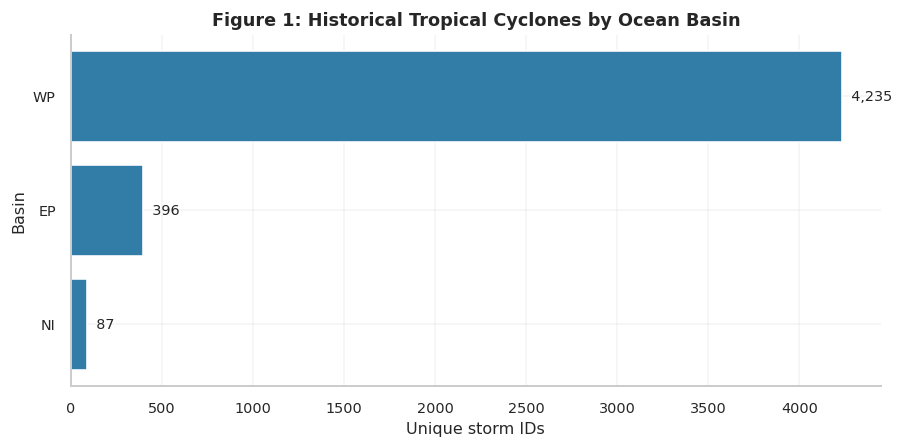

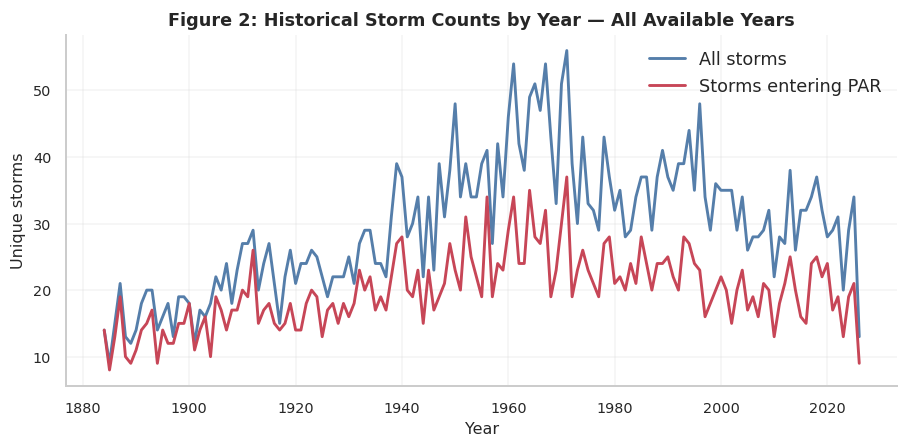

In [118]:
# FIGURE B01 — Number of unique storms by basin
fig,ax=plt.subplots(figsize=(8,4))
view=basin_table.sort_values("unique_storms")
ax.barh(view["BASIN"].astype(str),view["unique_storms"],color="#327DA8")
ax.set(title="Figure 1: Historical Tropical Cyclones by Ocean Basin",xlabel="Unique storm IDs",ylabel="Basin")
for i,v in enumerate(view["unique_storms"]): ax.text(v,i,f"  {v:,}",va="center",fontsize=9)
plt.tight_layout(); plt.show()

# FIGURE B02 — Annual storm counts (all basins vs entered PAR)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(annual_table["year"],annual_table["all_storms"],color="#557EAA",label="All storms",lw=1.8)
ax.plot(annual_table["year"],annual_table["par_storms"],color="#C74657",label="Storms entering PAR",lw=1.8)
ax.set(title="Figure 2: Historical Storm Counts by Year — All Available Years",xlabel="Year",ylabel="Unique storms")
ax.legend(frameon=False);plt.tight_layout();plt.show()

In [119]:
# MAP HELPERS — all storm IDs included; decimate only displayed observation points
BASIN_COLORS={"NA":"#D76755","EP":"#D49A37","WP":"#CB4360",
              "NI":"#409989","SI":"#5583B9","SP":"#879F5B","SA":"#A67CBA"}
BASIN_NAMES={"NA":"North Atlantic","EP":"East North Pacific",
             "WP":"West North Pacific","NI":"North Indian",
             "SI":"South Indian","SP":"South Pacific","SA":"South Atlantic"}

def split_track(lons,lats,stride=MAP_POINT_STRIDE):
    # All storms retained; only visualization points are thinned.
    ix=list(range(0,len(lons),max(1,stride)))
    if len(lons) and ix[-1] != len(lons)-1: ix.append(len(lons)-1)
    xs,ys=[],[]
    previous=None
    for k in ix:
        x,y=float(lons[k]),float(lats[k])
        if previous is not None and abs(x-previous)>180:
            xs.append(None);ys.append(None)
        xs.append(x);ys.append(y);previous=x
    xs.append(None);ys.append(None)
    return xs,ys

def map_style(fig,title,lon_range=None,lat_range=None,projection="equirectangular"):
    fig.update_geos(projection_type=projection,showland=True,landcolor="#F2F0E9",
                    showocean=True,oceancolor="#E7F3FA",showcoastlines=True,
                    coastlinecolor="#7F99AB",showcountries=True,countrycolor="#BBC7CF")
    if lon_range:
        fig.update_geos(lonaxis=dict(range=lon_range,showgrid=True,dtick=10,gridcolor="#D9E6ED"),
                        lataxis=dict(range=lat_range,showgrid=True,dtick=10,gridcolor="#D9E6ED"))
    fig.update_layout(title=dict(text=title,x=0.04),height=650,
                      margin=dict(l=15,r=15,t=100,b=20),paper_bgcolor="white",
                      legend=dict(orientation="h",y=1.04,x=0.04))
    return fig

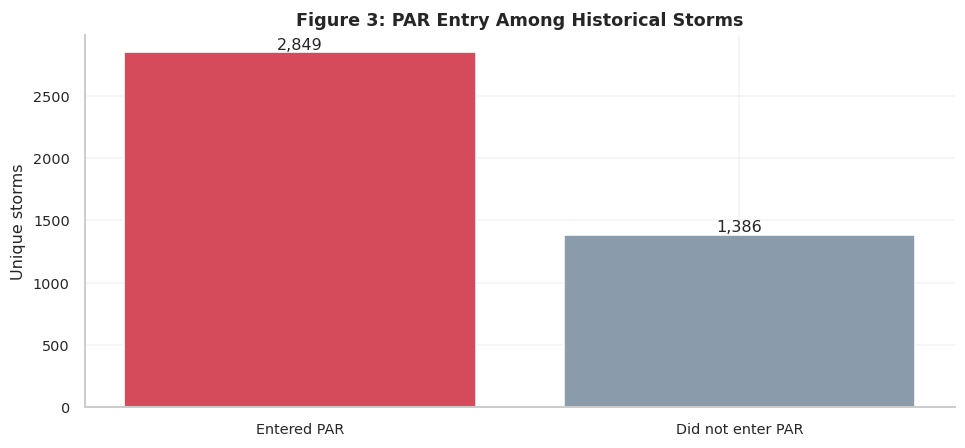

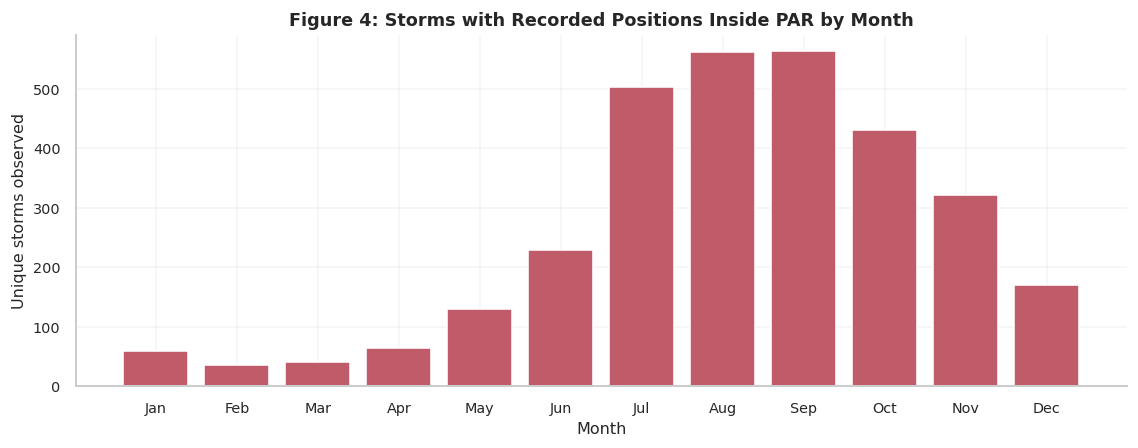

Monthly totals may double-count storms spanning months; segment-only crossings are not month-assigned.


In [120]:
# FIGURE B03 — PAR participation and monthly occurrences
par_nonpar=pd.Series({"Entered PAR":par_count,"Did not enter PAR":max(all_storms-par_count,0)})
fig,ax=plt.subplots(figsize=(8.5,4))
ax.bar(par_nonpar.index,par_nonpar.values,color=["#D54B5B","#8A9BAB"])
for i,v in enumerate(par_nonpar.values): ax.text(i,v,f"{v:,}",ha="center",va="bottom")
ax.set(title="Figure 3: PAR Entry Among Historical Storms",ylabel="Unique storms")
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(10,4))
ax.bar(month_table["month_name"],month_table["unique_storms_observed_in_par"],color="#C05C6A")
ax.set(title="Figure 4: Storms with Recorded Positions Inside PAR by Month",xlabel="Month",ylabel="Unique storms observed")
plt.tight_layout();plt.show()
print("Monthly totals may double-count storms spanning months; segment-only crossings are not month-assigned.")

In [121]:
# FIGURE B04 — Global historical storm tracks by basin
# Only if df_ib contains multiple basins. Each storm is shown using its modal basin.
fig=go.Figure()
for basin,color in BASIN_COLORS.items():
    ids=set(summary.loc[summary["basin"].eq(basin),"SID"])
    subset=tracks.loc[tracks["SID"].isin(ids)]
    if subset.empty: continue
    lon_all,lat_all=[],[]
    for sid,g in subset.groupby("SID",sort=False):
        xs,ys=split_track(g["LON"].to_numpy(),g["LAT"].to_numpy())
        lon_all.extend(xs);lat_all.extend(ys)
    fig.add_trace(go.Scattergeo(lon=lon_all,lat=lat_all,mode="lines",
                    line=dict(color=color,width=0.75),opacity=0.52,
                    name=f"{BASIN_NAMES[basin]} ({len(ids):,})",hoverinfo="skip"))
map_style(fig,"<b>Historical Tropical Cyclone Tracks by Basin</b><br><sup>All available years; plotted positions thinned for speed</sup>",projection="natural earth")
fig.show()

# FIGURE B05 — ALL PAR-entering storm tracks with correct PAGASA polygon
partracks=tracks.loc[tracks["STORM_ENTERED_PAR"]]
all_lons,all_lats=[],[]
for sid,g in partracks.groupby("SID",sort=False):
    xs,ys=split_track(g["LON"].to_numpy(),g["LAT"].to_numpy())
    all_lons.extend(xs);all_lats.extend(ys)
fig=go.Figure()
fig.add_trace(go.Scattergeo(lon=all_lons,lat=all_lats,mode="lines",
                 line=dict(color="#CA4257",width=0.85),opacity=0.43,
                 name=f"Entered PAR ({len(entered_ids):,})",hoverinfo="skip"))
closed=PAR_COORDS+[PAR_COORDS[0]]
fig.add_trace(go.Scattergeo(lon=[x for x,y in closed],lat=[y for x,y in closed],
                 mode="lines",fill="toself",fillcolor="rgba(210,48,65,0.06)",
                 line=dict(color="#A7213A",width=3,dash="dash"),name="PAGASA PAR"))
map_style(fig,"<b>Historical Storm Tracks Entering the Philippine Area of Responsibility</b><br><sup>All available years, all PAR storms</sup>",lon_range=[100,165],lat_range=[-5,45])
fig.show()

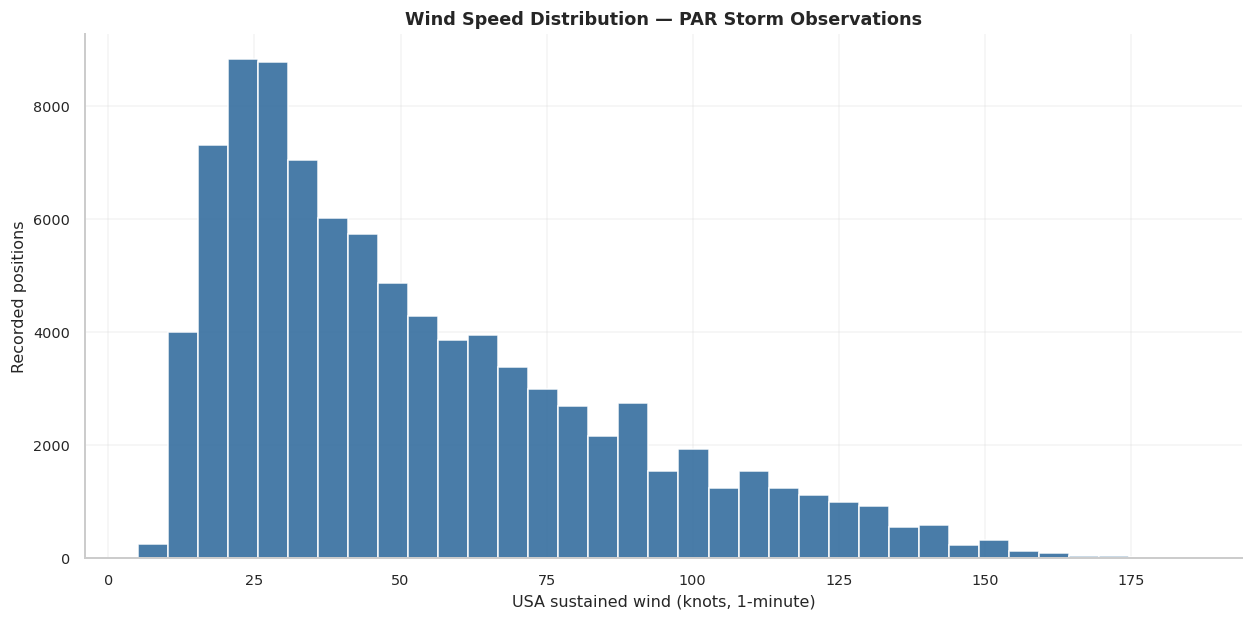

Valid wind observations: 91,289


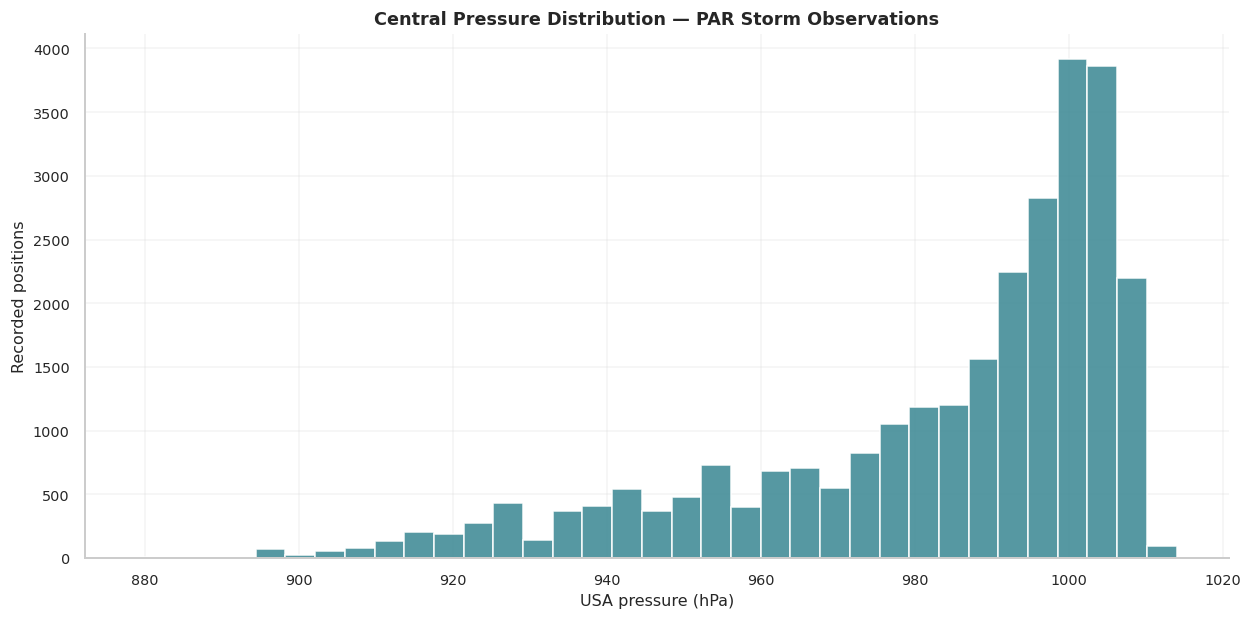

Valid pressure observations: 27,818


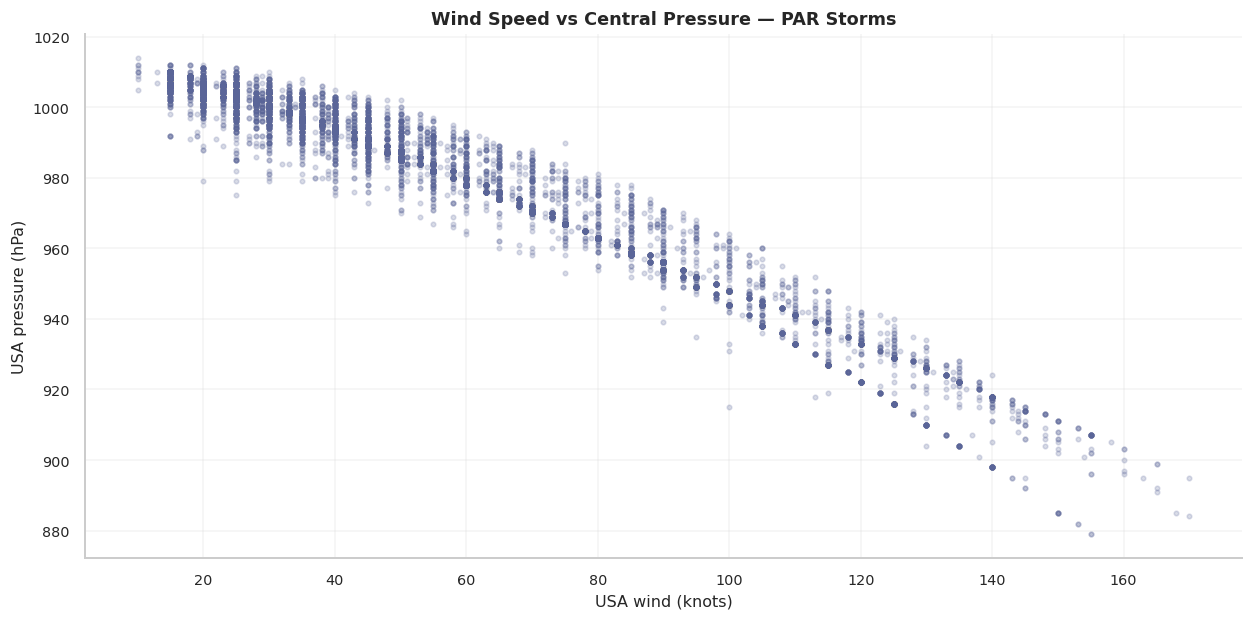

Available matched records: 27,818 (displayed: 12,000)


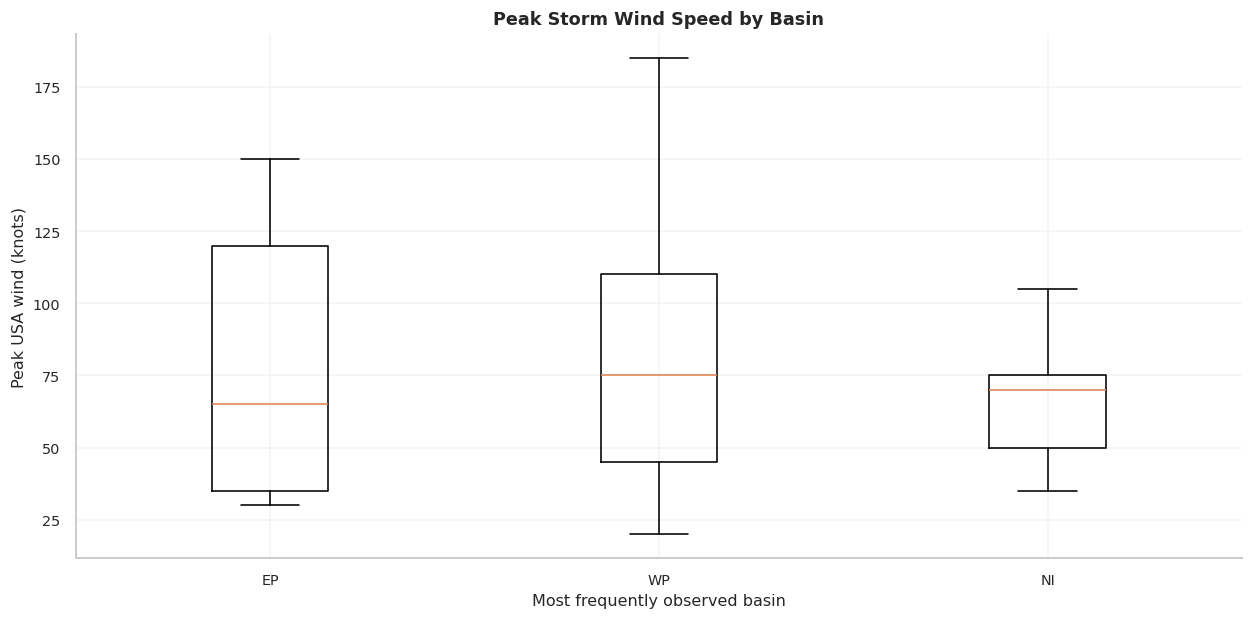

In [122]:
# GRAPH B06 — Wind intensity distribution for PAR storms
p=s.loc[s["SID"].isin(entered_ids)]
x=p["wind_kt"].dropna()
fig,ax=plt.subplots()
ax.hist(x,bins=35,color="#356E9F",edgecolor="white",alpha=.9)
ax.set(title="Wind Speed Distribution — PAR Storm Observations",xlabel="USA sustained wind (knots, 1-minute)",ylabel="Recorded positions")
plt.tight_layout();plt.show()
print(f"Valid wind observations: {len(x):,}")

# GRAPH B07 — Minimum central pressure distribution for PAR storms
x=p["pressure_hpa"].dropna()
fig,ax=plt.subplots()
ax.hist(x,bins=35,color="#438D98",edgecolor="white",alpha=.9)
ax.set(title="Central Pressure Distribution — PAR Storm Observations",xlabel="USA pressure (hPa)",ylabel="Recorded positions")
plt.tight_layout();plt.show()
print(f"Valid pressure observations: {len(x):,}")

# GRAPH B08 — Wind speed against pressure (sample drawn only for rendering)
wpairs=p[["wind_kt","pressure_hpa"]].dropna()
plot_pairs=wpairs.sample(n=min(12000,len(wpairs)),random_state=42) if len(wpairs) else wpairs
fig,ax=plt.subplots()
ax.scatter(plot_pairs["wind_kt"],plot_pairs["pressure_hpa"],s=8,alpha=.22,color="#5A6598")
ax.set(title="Wind Speed vs Central Pressure — PAR Storms",xlabel="USA wind (knots)",ylabel="USA pressure (hPa)")
plt.tight_layout();plt.show()
print(f"Available matched records: {len(wpairs):,} (displayed: {len(plot_pairs):,})")

# GRAPH B09 — Peak wind speed by basin (each storm counted once per modal basin)
valid_peak=summary.dropna(subset=["peak_wind_kt"])
groups=[valid_peak.loc[valid_peak["basin"].eq(b),"peak_wind_kt"].values
        for b in BASIN_COLORS if (valid_peak["basin"]==b).any()]
labels=[b for b in BASIN_COLORS if (valid_peak["basin"]==b).any()]
fig,ax=plt.subplots()
if groups: ax.boxplot(groups,tick_labels=labels,showfliers=False,patch_artist=False)
ax.set(title="Peak Storm Wind Speed by Basin",xlabel="Most frequently observed basin",ylabel="Peak USA wind (knots)")
plt.tight_layout();plt.show()

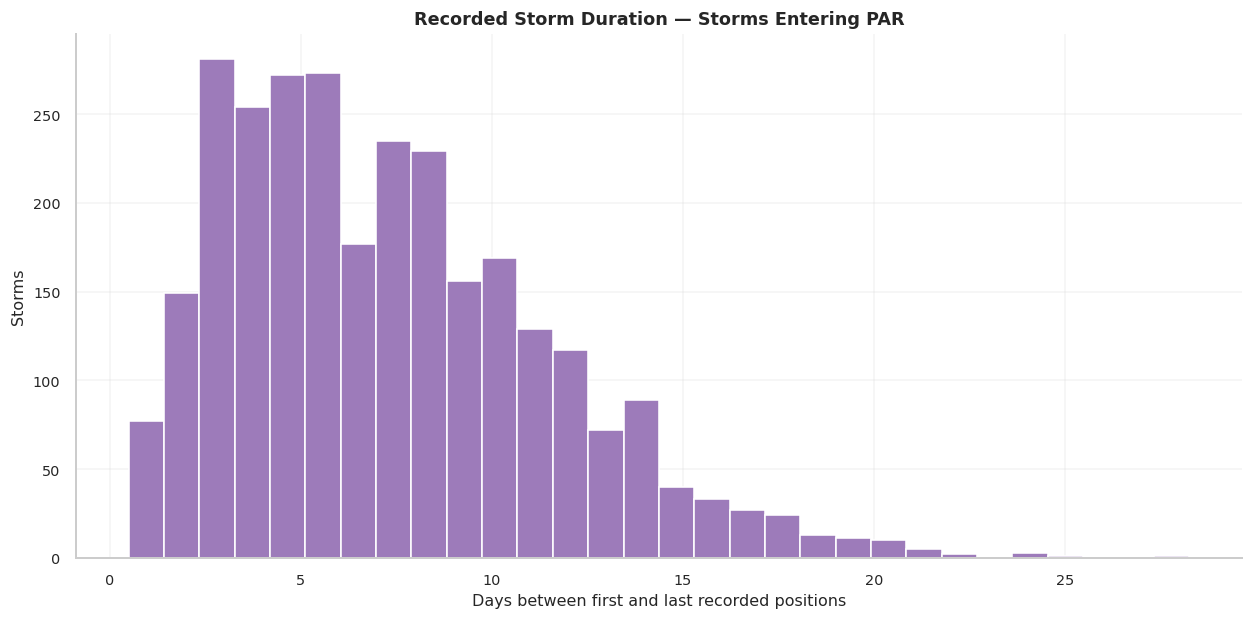

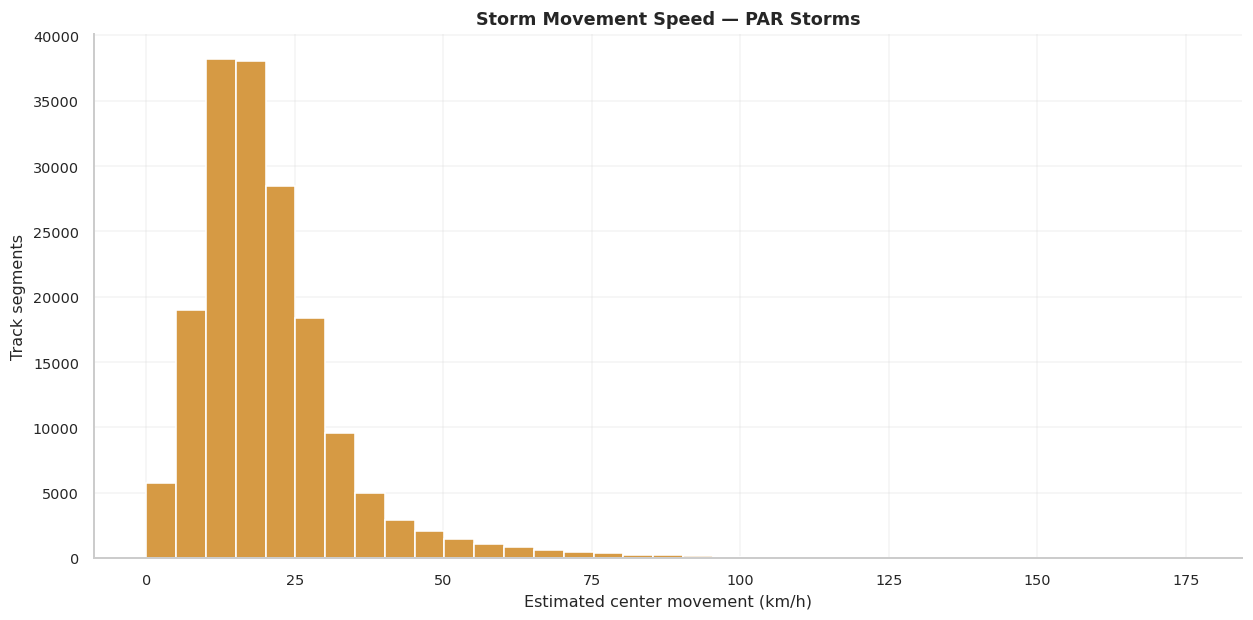

Positions exceeding review threshold (180 km/h): 3


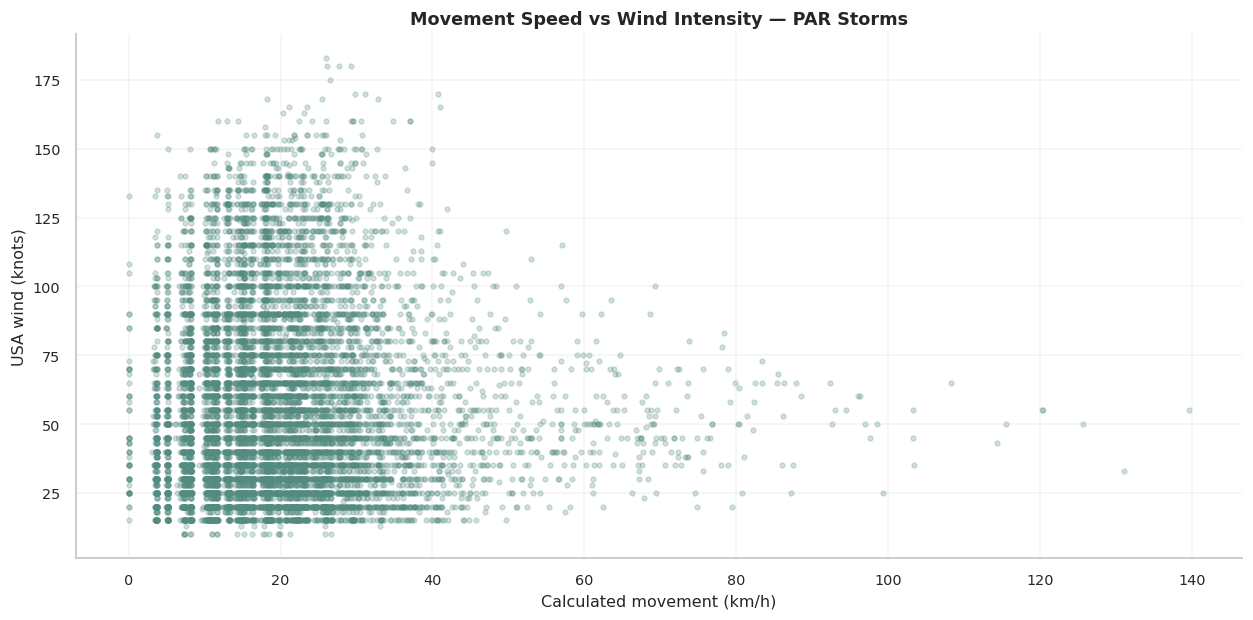

In [123]:
# GRAPH B10 — Storm duration (PAR storms)
selected=summary[summary["entered_par"]]
fig,ax=plt.subplots()
ax.hist(selected["duration_days"].dropna(),bins=30,color="#9D7BBA",edgecolor="white")
ax.set(title="Recorded Storm Duration — Storms Entering PAR",xlabel="Days between first and last recorded positions",ylabel="Storms")
plt.tight_layout();plt.show()

# GRAPH B11 — Calculated storm translation speed (PAR storms)
spd=p.loc[p["movement_kmh"].le(REVIEW_SPEED_KMH),"movement_kmh"].dropna()
fig,ax=plt.subplots()
ax.hist(spd,bins=35,color="#D69A44",edgecolor="white")
ax.set(title="Storm Movement Speed — PAR Storms",xlabel="Estimated center movement (km/h)",ylabel="Track segments")
plt.tight_layout();plt.show()
print(f"Positions exceeding review threshold ({REVIEW_SPEED_KMH} km/h): {int(p['speed_flag'].sum()):,}")

# GRAPH B12 — Movement speed vs wind intensity
paired=p.loc[p["movement_kmh"].le(REVIEW_SPEED_KMH),["movement_kmh","wind_kt"]].dropna()
paired_plot=paired.sample(n=min(len(paired),12000),random_state=42) if len(paired) else paired
fig,ax=plt.subplots()
ax.scatter(paired_plot["movement_kmh"],paired_plot["wind_kt"],s=9,alpha=.25,color="#548B80")
ax.set(title="Movement Speed vs Wind Intensity — PAR Storms",xlabel="Calculated movement (km/h)",ylabel="USA wind (knots)")
plt.tight_layout();plt.show()

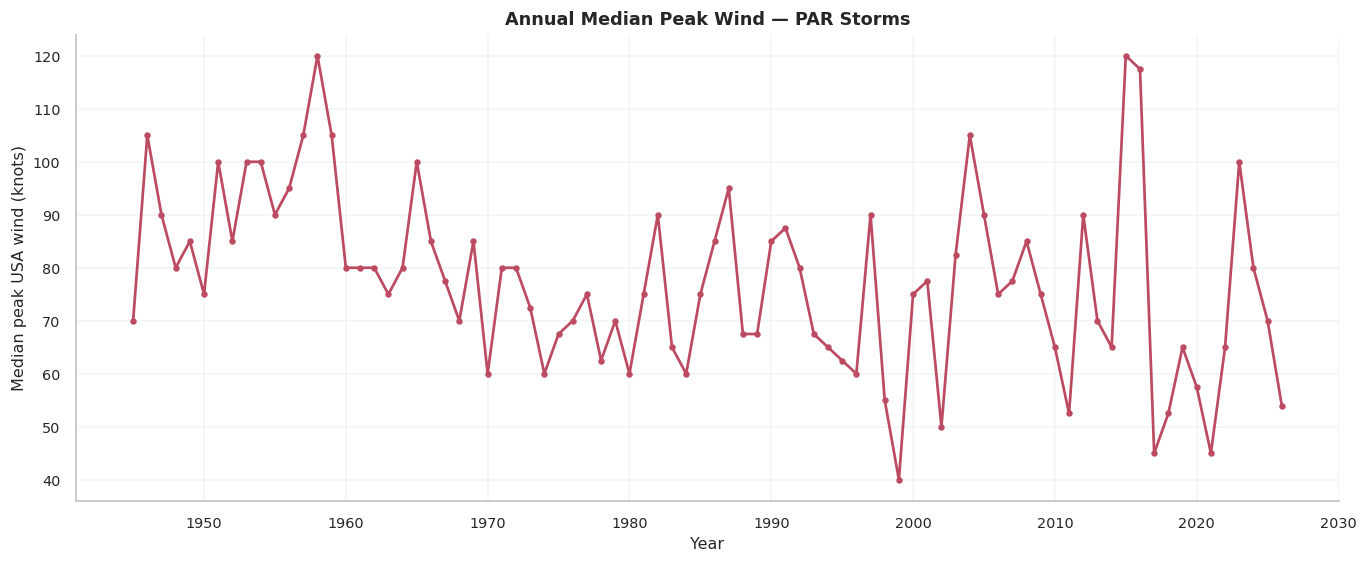

Caution: earlier years may have different agency measurement coverage.


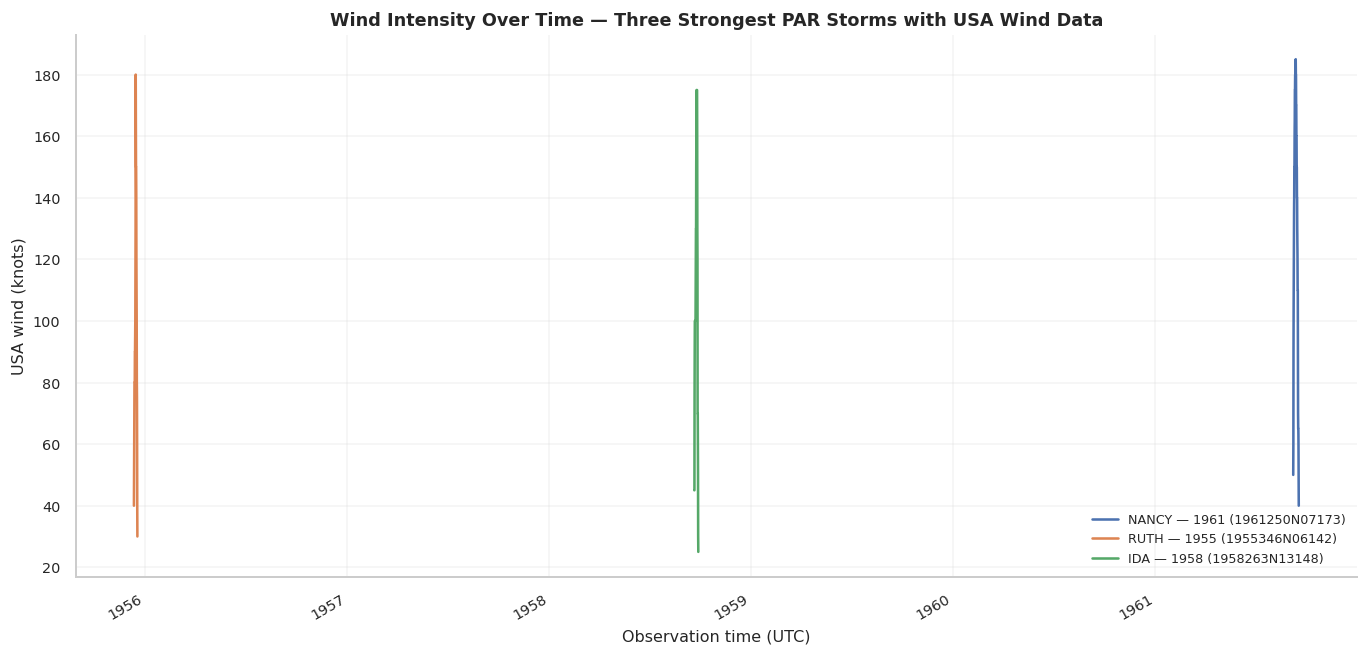

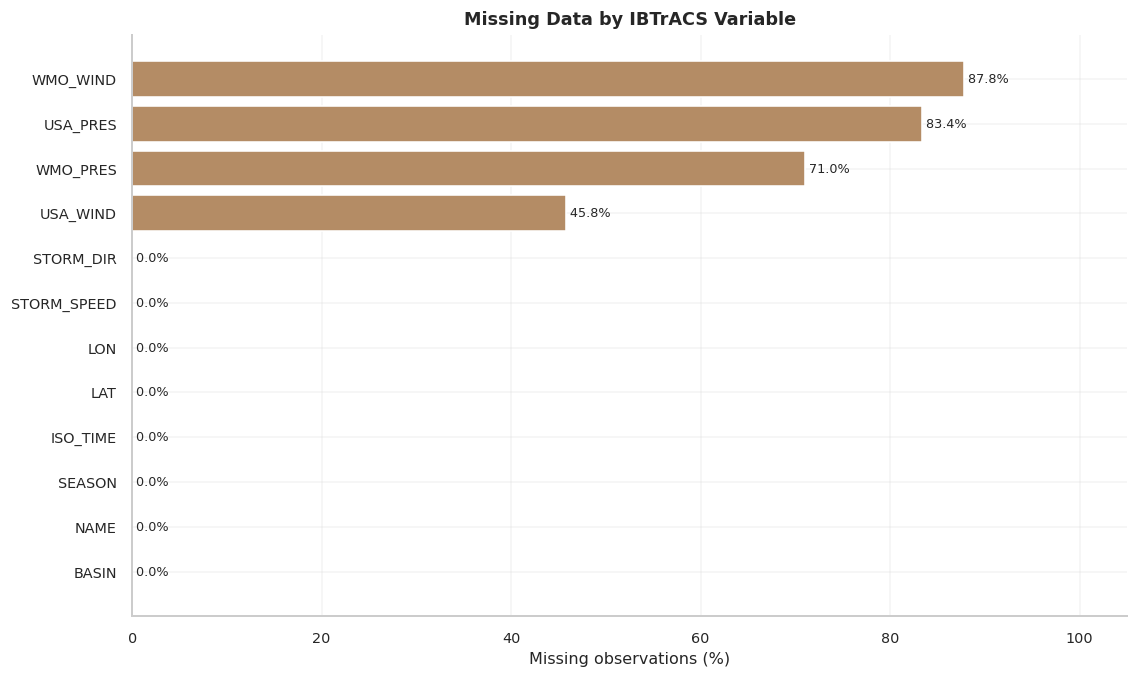

In [124]:
# GRAPH B13 — Annual median peak wind speed of PAR storms
byyr=summary.loc[summary["entered_par"] & summary["peak_wind_kt"].notna()].groupby("year")["peak_wind_kt"].median()
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(byyr.index,byyr.values,color="#BC4B62",lw=1.7,marker="o",markersize=3)
ax.set(title="Annual Median Peak Wind — PAR Storms",xlabel="Year",ylabel="Median peak USA wind (knots)")
plt.tight_layout();plt.show()
print("Caution: earlier years may have different agency measurement coverage.")

# GRAPH B14 — Individual intensity development for strongest PAR storms
selected_ids=(summary.loc[summary["entered_par"] & summary["peak_wind_kt"].notna()]
              .nlargest(3,"peak_wind_kt"))
fig,ax=plt.subplots(figsize=(12,5.8))
for _,r in selected_ids.iterrows():
    g=s.loc[s["SID"].eq(r["SID"])]
    ax.plot(g["ISO_TIME"],g["wind_kt"],lw=1.6,
            label=f"{r['name']} — {r['year']} ({r['SID']})")
ax.set(title="Wind Intensity Over Time — Three Strongest PAR Storms with USA Wind Data",
       xlabel="Observation time (UTC)",ylabel="USA wind (knots)")
ax.legend(frameon=False,fontsize=8)
fig.autofmt_xdate();plt.tight_layout();plt.show()

# MAP B15 — Selected PAR tracks colored by wind intensity
# The entire all-years PAR map is B05; here we display the 6 strongest for readability.
chosen=summary.loc[summary["entered_par"] & summary["peak_wind_kt"].notna()].nlargest(6,"peak_wind_kt")
fig=go.Figure()
for i,(_,r) in enumerate(chosen.iterrows()):
    g=s.loc[s["SID"].eq(r["SID"])].sort_values("ISO_TIME")
    fig.add_trace(go.Scattergeo(lon=g["LON"],lat=g["LAT"],mode="lines+markers",
        name=f"{r['name']} ({r['year']})",line=dict(color="#526A7A",width=1.5),
        marker=dict(size=5,color=g["wind_kt"],colorscale="Turbo",cmin=0,cmax=170,
                    showscale=(i==0),colorbar=dict(title="Wind (kt)")),
        hovertemplate="Lat %{lat:.1f}, Lon %{lon:.1f}<extra>%{fullData.name}</extra>"))
closed=PAR_COORDS+[PAR_COORDS[0]]
fig.add_trace(go.Scattergeo(lon=[x for x,y in closed],lat=[y for x,y in closed],
    mode="lines",line=dict(color="#B92746",width=2,dash="dash"),name="PAGASA PAR"))
map_style(fig,"<b>Selected Strongest Historical PAR Storms — Wind Intensity Along Track</b><br><sup>Top six by observed USA peak wind; marker color = wind speed</sup>",lon_range=[100,165],lat_range=[-5,45])
fig.show()

# GRAPH B16 — Missingness percentages of key NOAA fields
cols=["BASIN","NAME","SEASON","ISO_TIME","LAT","LON",
      "USA_WIND","USA_PRES","WMO_WIND","WMO_PRES","STORM_SPEED","STORM_DIR"]
miss=ib[cols].isna().mean().mul(100).sort_values(ascending=True)
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(miss.index,miss.values,color="#B48C65")
ax.set(title="Missing Data by IBTrACS Variable",xlabel="Missing observations (%)",xlim=(0,105))
for i,v in enumerate(miss.values): ax.text(v,i,f" {v:.1f}%",va="center",fontsize=8)
plt.tight_layout();plt.show()


#### Galloway EDA

1. Part A — Summary tables
2. Part B — Visualization



In [84]:
from pathlib import Path
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

DATA_FILE = Path('/content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/impact/Impact_Data.csv')
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'File not found: {DATA_FILE}\nCheck Drive mount and filename capitalization.')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'semibold', 'axes.titlesize': 11,
                     'axes.labelsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9})
print('Selected Galloway file:', DATA_FILE)
print(f'File size: {DATA_FILE.stat().st_size / (1024**2):,.2f} MiB')


Selected Galloway file: /content/drive/MyDrive/Colab Notebooks/data/dsp_final_project/impact/Impact_Data.csv
File size: 0.09 MiB


In [85]:
# The 11 source headers supplied by the researcher (case and spacing preserved).
EXPECTED_COLUMNS = [
    'Cyclone Name',
    'Province',
    'Deaths',
    'Affected',
    'Houses destroyed',
    'Houses damaged',
    'Total Houses',
    'Damage to Infrastructure (PhP)',
    'Damage to Agriculture + Fisheries (PhP)',
    'Year',
    'Category'
]

try:
    df_impact_raw = pd.read_csv(DATA_FILE, encoding='utf-8-sig')
except UnicodeDecodeError:
    df_impact_raw = pd.read_csv(DATA_FILE, encoding='latin-1')

# Strip stray spaces from CSV headers only; do not infer alternate column names.
df_impact_raw.columns = df_impact_raw.columns.astype(str).str.strip()
if df_impact_raw.columns.duplicated().any():
    raise ValueError('Duplicate CSV column headers after stripping whitespace. Inspect the source.')

missing_cols = [col for col in EXPECTED_COLUMNS if col not in df_impact_raw.columns]
extra_cols = [col for col in df_impact_raw.columns if col not in EXPECTED_COLUMNS]
print('Rows:', len(df_impact_raw), '| Columns:', len(df_impact_raw.columns))
print('Missing expected headers:', missing_cols if missing_cols else 'None')
print('Additional headers:', extra_cols if extra_cols else 'None')
if missing_cols:
    raise ValueError('Missing required CSV columns: ' + ', '.join(missing_cols) +
                     '\nCheck the header row of Impact_Data.csv; no automatic guessing is used.')

display(df_impact_raw.head(6))


Rows: 1266 | Columns: 11
Missing expected headers: None
Additional headers: None


,Cyclone Name,Province,Deaths,Affected,Houses destroyed,Houses damaged,Total Houses,Damage to Infrastructure (PhP),Damage to Agriculture + Fisheries (PhP),Year,Category
0,Conson,Metro Manila,2.0,2802.0,62.0,0.0,62,1705000.0,0.0,2010,Strong typhoon
1,Conson,Aurora,0.0,187.0,0.0,0.0,0,19300000.0,0.0,2010,Strong typhoon
2,Conson,Bataan,10.0,68692.0,232.0,2695.0,2927,4950000.0,579332.0,2010,Strong typhoon
3,Conson,Bulacan,3.0,189.0,0.0,0.0,0,23761000.0,0.0,2010,Strong typhoon
4,Conson,Pampanga,0.0,221.0,0.0,0.0,0,0.0,0.0,2010,Strong typhoon
5,Conson,Batangas,4.0,11605.0,102.0,1138.0,1240,15000000.0,0.0,2010,Strong typhoon


In [86]:
# Explicit 1:1 mapping — no column guessing.
mapping = {
    'storm': 'Cyclone Name',
    'province': 'Province',
    'deaths': 'Deaths',
    'affected': 'Affected',
    'houses_destroyed': 'Houses destroyed',
    'houses_damaged': 'Houses damaged',
    'total_houses': 'Total Houses',
    'infra_loss': 'Damage to Infrastructure (PhP)',
    'agri_loss': 'Damage to Agriculture + Fisheries (PhP)',
    'year': 'Year',
    'category': 'Category',
}

mapping_table = pd.DataFrame({
    'Source column': list(mapping.values()),
    'EDA working field': list(mapping.keys()),
})
print('Verified source-to-working-column mapping:')
display(mapping_table)


Verified source-to-working-column mapping:


,Source column,EDA working field
0,Cyclone Name,storm
1,Province,province
2,Deaths,deaths
3,Affected,affected
4,Houses destroyed,houses_destroyed
5,Houses damaged,houses_damaged
6,Total Houses,total_houses
7,Damage to Infrastructure (PhP),infra_loss
8,Damage to Agriculture + Fisheries (PhP),agri_loss
9,Year,year


In [87]:
# EDA working copy; never write back to Impact_Data.csv.
df = df_impact_raw.rename(columns={src: dst for dst, src in mapping.items()}).copy()

for field in ['storm', 'province', 'category']:
    df[field] = df[field].astype('string').str.strip()
    df.loc[df[field].str.lower().isin(['nan', 'none', 'null', '']), field] = pd.NA

df['year'] = pd.to_numeric(df['year'], errors='coerce')

# Commas, Philippine peso signs, and accounting-style negative notation are
# handled ONLY in this numeric EDA copy; missing stays missing, zero stays zero.
def to_numeric_impact(series):
    txt = series.astype('string').str.replace(',', '', regex=False)
    txt = txt.str.replace('₱', '', regex=False).str.replace('PHP', '', regex=False)
    txt = txt.str.strip().str.replace(r'^\(([^)]+)\)$', r'-\1', regex=True)
    return pd.to_numeric(txt, errors='coerce')

MEASURES = ['affected', 'deaths', 'houses_damaged', 'houses_destroyed', 'agri_loss', 'infra_loss']
for field in MEASURES + ['total_houses']:
    df[field] = to_numeric_impact(df[field])

# Descriptive event key ONLY: storm names can recur between years.
df['event_label'] = df['storm'].fillna('UNKNOWN').astype(str) + ' (' + (
    df['year'].astype('Int64').astype('string').fillna('?').astype(str)
) + ')'

metric_names = {
    'affected': 'Affected population',
    'deaths': 'Deaths',
    'houses_damaged': 'Houses damaged',
    'houses_destroyed': 'Houses destroyed',
    'total_houses': 'Total Houses (source; meaning to verify)',
    'agri_loss': 'Agriculture + fisheries loss (nominal PHP)',
    'infra_loss': 'Infrastructure loss (nominal PHP)'
}

print('EDA working copy:', df.shape, '| original remains unchanged:', df_impact_raw.shape)
print('Years:', int(df['year'].min()) if df['year'].notna().any() else '?',
      'to', int(df['year'].max()) if df['year'].notna().any() else '?')


EDA working copy: (1266, 12) | original remains unchanged: (1266, 11)
Years: 2010 to 2020


**Part A — Summary Tables**

In [88]:
def show_four_tables(items, max_rows=16):
    """items = [(title, DataFrame), ...] | <= 4. Outputs one 2x2 HTML grid."""
    if not 1 <= len(items) <= 4:
        raise ValueError('Each cell must display between 1 and 4 tables.')
    cards = []
    for title, table in items:
        if not isinstance(table, pd.DataFrame): table = pd.DataFrame(table)
        table_html = table.head(max_rows).to_html(index=False, escape=True, border=0, classes='impacttbl')
        extra = (f'<div style="font-size:11px;color:#777">Showing first {max_rows} of {len(table)} rows</div>'
                 if len(table)>max_rows else '')
        cards.append(f'<div style="min-width:0;border:1px solid #D9E0E6;border-radius:9px;padding:10px">'
                     f'<div style="font-weight:700;margin-bottom:8px">{html.escape(title)}</div>'
                     f'<div style="max-height:325px;overflow:auto">{table_html}</div>{extra}</div>')
    style = """<style>.impacttbl{width:100%;font-size:12px;border-collapse:collapse}
    .impacttbl th{background:#EDF3F8;text-align:left;position:sticky;top:0}
    .impacttbl td,.impacttbl th{padding:5px 6px;border-bottom:1px solid #E7ECF0;white-space:normal}
    </style>"""
    display(HTML(style+'<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:14px">'+''.join(cards)+'</div>'))

def safe_group(col):
    return df.dropna(subset=[col]).copy()

def brief_numeric(x):
    x = pd.to_numeric(x, errors='coerce').dropna()
    if x.empty: return {'n':0,'mean':np.nan,'median':np.nan,'p95':np.nan,'max':np.nan}
    return {'n': len(x), 'mean': x.mean(), 'median':x.median(), 'p95':x.quantile(.95), 'max':x.max()}

In [89]:
years = df['year'].dropna()
overview = pd.DataFrame({
    'Measure': ['Rows', 'Original source columns', 'Unique cyclone–year events',
                'Unique provinces', 'Earliest year', 'Latest year', 'Exact duplicate rows'],
    'Value': [len(df), len(df_impact_raw.columns),
              df.loc[df['storm'].notna(), 'event_label'].nunique(),
              df['province'].nunique(), years.min() if len(years) else 'Unknown',
              years.max() if len(years) else 'Unknown',
              int(df_impact_raw.duplicated().sum())]
})
types = pd.DataFrame({'Source column': df_impact_raw.columns,
                      'Data type': [str(x) for x in df_impact_raw.dtypes]})
example = df[['event_label', 'province', 'year', 'category', 'affected', 'deaths',
              'houses_damaged', 'houses_destroyed', 'total_houses']].head(8).copy()
show_four_tables([
    ('A01.1 — Dataset overview', overview),
    ('A01.2 — Original column types', types),
    ('A01.3 — Fixed field mapping', mapping_table),
    ('A01.4 — Working sample (first 8 rows)', example)
])

Measure,Value
Rows,1266
Original source columns,11
Unique cyclone–year events,85
Unique provinces,80
Earliest year,2010
Latest year,2020
Exact duplicate rows,0
Source column,Data type
Cyclone Name,object
Province,object


In [90]:
annual = (df.dropna(subset=['year','storm']).groupby('year')['event_label'].nunique()
          .rename('unique_storms').reset_index().sort_values('year'))
annual['year'] = annual['year'].astype('Int64')
province_events = (df.dropna(subset=['province','storm']).groupby('province')['event_label']
                   .nunique().sort_values(ascending=False).head(15)
                   .rename('reported_storms').reset_index())
event_provinces = (df.dropna(subset=['province','storm']).groupby('event_label')['province']
                   .nunique().sort_values(ascending=False).head(15)
                   .rename('provinces_with_records').reset_index())
coverage_by_year = (df.dropna(subset=['year','province']).groupby('year')['province']
                    .nunique().rename('provinces_covered').reset_index().sort_values('year'))
show_four_tables([
 ('A02.1 — Storms by year', annual), ('A02.2 — Provinces by year', coverage_by_year),
 ('A02.3 — Provinces with most recorded storms', province_events),
 ('A02.4 — Storms with widest province coverage', event_provinces)
])

year,unique_storms
2010,2
2011,11
2012,7
2013,9
2014,10
2015,9
2016,7
2017,10
2018,6
2019,7


In [91]:
quality_rows, status_rows, dist_rows = [], [], []
QUALITY_MEASURES = MEASURES + ['total_houses']
for field in QUALITY_MEASURES:
    x = df[field]
    quality_rows.append({'indicator': field, 'missing': int(x.isna().sum()),
                         'missing_%': round(x.isna().mean()*100, 1),
                         'negative': int((x < 0).sum())})
    status_rows.append({'indicator': field, 'missing': int(x.isna().sum()),
                        'zero': int((x == 0).sum()), 'positive': int((x > 0).sum()),
                        'negative': int((x < 0).sum())})
    dist_rows.append({'indicator': field, **brief_numeric(x[x >= 0])})
quality = pd.DataFrame(quality_rows)
status = pd.DataFrame(status_rows)
stats = pd.DataFrame(dist_rows).round(2)
repeats = df[df.duplicated(['event_label', 'province'], keep=False)]
duplicate_summary = (repeats.groupby(['event_label', 'province']).size()
                     .rename('rows').reset_index().sort_values('rows', ascending=False).head(15))
show_four_tables([
    ('A03.1 — Missing values / negatives', quality),
    ('A03.2 — Missing vs zero vs positive', status),
    ('A03.3 — Magnitude statistics', stats),
    ('A03.4 — Repeated cyclone–province keys', duplicate_summary)
])

In [92]:
raw_totals = pd.DataFrame([
    {'indicator': field,
     'nonmissing': int(df[field].notna().sum()),
     'recorded_total': float(df[field].where(df[field] >= 0).sum(min_count=1))
                       if df[field].notna().any() else np.nan,
     'units': 'nominal PHP' if 'loss' in field else 'count'}
    for field in MEASURES
])
rank_metric = 'affected'
top_storms = (df.groupby('event_label')[rank_metric].sum(min_count=1)
              .dropna().nlargest(15).rename(f'total_{rank_metric}').reset_index())
top_provinces = (df.groupby('province')[rank_metric].sum(min_count=1)
                .dropna().nlargest(15).rename(f'total_{rank_metric}').reset_index())
standardize = pd.DataFrame([
    {'field': 'Cyclone Name + Year', 'phase_4_check': 'Map cyclone/year to unique IBTrACS SID; audit spelling and aliases'},
    {'field': 'Province', 'phase_4_check': 'Match to PSGC/GADM province codes and historical boundaries'},
    {'field': 'Category', 'phase_4_check': 'Check unique labels; document classification scheme and source'},
    {'field': 'Deaths / Affected', 'phase_4_check': 'Check missing vs zero, duplicates, and implausible values'},
    {'field': 'Houses damaged / Houses destroyed', 'phase_4_check': 'Check overlapping definitions and values'},
    {'field': 'Total Houses', 'phase_4_check': 'Check if damaged + destroyed; DO NOT assume provincial housing stock'},
    {'field': 'Infrastructure and agricultural losses (PhP)',
     'phase_4_check': 'Verify units, negative records, missing values, price year, and components'},
    {'field': 'Year', 'phase_4_check': 'Check invalid years, event identifier consistency, and historical coverage'},
    {'field': 'Population and total housing stock',
     'phase_4_check': 'Require external year-matched denominators before computing impact rates'}
])
show_four_tables([
    ('A04.1 — Recorded impact totals', raw_totals),
    ('A04.2 — Highest events by affected population', top_storms),
    ('A04.3 — Highest provinces by affected population', top_provinces),
    ('A04.4 — Explicit standardization register', standardize)
])


In [93]:
# Only compare rows where all three housing values exist.
housing = df[['houses_damaged', 'houses_destroyed', 'total_houses']].dropna().copy()
housing['damaged_plus_destroyed'] = housing['houses_damaged'] + housing['houses_destroyed']
housing['difference'] = housing['total_houses'] - housing['damaged_plus_destroyed']
housing['total_matches_sum'] = np.isclose(
    housing['total_houses'], housing['damaged_plus_destroyed'], rtol=0, atol=0.001
)

housing_summary = pd.DataFrame([
    {'Check': 'Rows with all 3 housing fields', 'Value': len(housing)},
    {'Check': 'Total Houses = Damaged + Destroyed', 'Value': int(housing['total_matches_sum'].sum())},
    {'Check': 'Total Houses differs from the sum', 'Value': int((~housing['total_matches_sum']).sum())},
    {'Check': 'Match rate (%)', 'Value': round(housing['total_matches_sum'].mean() * 100, 2)
                                if len(housing) else np.nan},
    {'Check': 'Total Houses < Damaged + Destroyed', 'Value': int((housing['difference'] < -0.001).sum())},
])

housing_examples = (housing.loc[~housing['total_matches_sum']]
                    .head(15).reset_index().rename(columns={'index': 'source_row'}))
category_table = (df['category'].fillna('(missing)').value_counts(dropna=False)
                  .rename_axis('Original category').rename('Records').reset_index())
category_by_year = (pd.crosstab(df['year'], df['category'], dropna=False)
                    .reset_index().rename(columns={'year': 'Year'}))
show_four_tables([
    ('A05.1 — Housing field consistency', housing_summary),
    ('A05.2 — Housing mismatches (up to 15)', housing_examples),
    ('A05.3 — Exact original category labels', category_table),
    ('A05.4 — Categories by year', category_by_year)
])
print('Caution: Even if Total Houses equals Damaged + Destroyed for every row,')
print('that does NOT establish total provincial housing stock. Use external census stock for housing rates.')


Caution: Even if Total Houses equals Damaged + Destroyed for every row,
that does NOT establish total provincial housing stock. Use external census stock for housing rates.


In [94]:
if 'df_ib' in globals() and mapping['storm'] is not None and 'NAME' in df_ib.columns:
    ibi = df_ib[['NAME'] + (['SEASON'] if 'SEASON' in df_ib.columns else [])].copy()
    ibi['name_key']=ibi['NAME'].astype('string').str.upper().str.replace(r'[^A-Z0-9]','',regex=True)
    ibi['year_key']=pd.to_numeric(ibi['SEASON'],errors='coerce') if 'SEASON' in ibi else np.nan
    iti = df[['storm','year']].dropna(subset=['storm']).drop_duplicates().copy()
    iti['name_key']=iti['storm'].astype('string').str.upper().str.replace(r'[^A-Z0-9]','',regex=True)
    iti['year_key']=iti['year']
    keys=['name_key','year_key'] if iti['year'].notna().any() and 'SEASON' in ibi.columns else ['name_key']
    lookup=ibi[keys].drop_duplicates().assign(potential_match=True)
    matched=iti.merge(lookup,on=keys,how='left')
    matched['potential_match']=matched['potential_match'].fillna(False)
    unmatched=matched[~matched['potential_match']][['storm','year']].head(15)
    coverage=pd.DataFrame([{'metric':'Unique impact storm entries','count':len(matched)},
                           {'metric':'Possible name/year matches','count':int(matched['potential_match'].sum())},
                           {'metric':'Unmatched','count':int((~matched['potential_match']).sum())}])
    show_four_tables([('A06.1 — Preliminary matching summary',coverage),
                      ('A06.2 — Unmatched storm labels (examples)',unmatched)])
else:
    print('Optional matching skipped: df_ib is not loaded here, or required storm columns are absent.')
    print('This does not affect the standalone Galloway EDA.')

Optional matching skipped: df_ib is not loaded here, or required storm columns are absent.
This does not affect the standalone Galloway EDA.


**2. Part B — Visualizations**

In [95]:
def plot_grid(title, artists, figsize=(16, 10)):
    """artists: 4 callables, each accepts one axis. One 2x2 figure only."""
    if len(artists)!=4: raise ValueError('Provide exactly four graph functions.')
    fig, axes=plt.subplots(2,2,figsize=figsize,constrained_layout=True)
    fig.suptitle(title,fontsize=17,fontweight='bold')
    for ax, draw in zip(axes.flat, artists):
        try:
            draw(ax)
        except Exception as e:
            ax.clear(); ax.text(.5,.5,f'Graph unavailable\n{str(e)[:90]}', ha='center',va='center',transform=ax.transAxes)
            ax.set_axis_off()
    plt.show()

def no_data(ax, title, message='No compatible records / field mapping'):
    ax.set_title(title); ax.text(.5,.5,message,ha='center',va='center',transform=ax.transAxes,wrap=True)
    ax.set_xticks([]); ax.set_yticks([])

def horiz_bars(ax, series, title, xlabel, n=12):
    if series is None or len(series)==0: return no_data(ax,title)
    top=series.dropna().sort_values(ascending=False).head(n).iloc[::-1]
    if top.empty: return no_data(ax,title)
    ax.barh(top.index.astype(str),top.values)
    ax.set_title(title);ax.set_xlabel(xlabel)

def clean_metric(metric):
    if mapping[metric] is None: return pd.Series(dtype='float64')
    return df[metric].dropna().loc[lambda s:s>=0]

def dist_plot(ax,metric,title):
    x=clean_metric(metric)
    if x.empty: return no_data(ax,title)
    ax.hist(np.log1p(x),bins=min(35,max(5,int(np.sqrt(len(x))))),edgecolor='white')
    ax.set(title=title,xlabel='log(1 + reported value)',ylabel='Records')

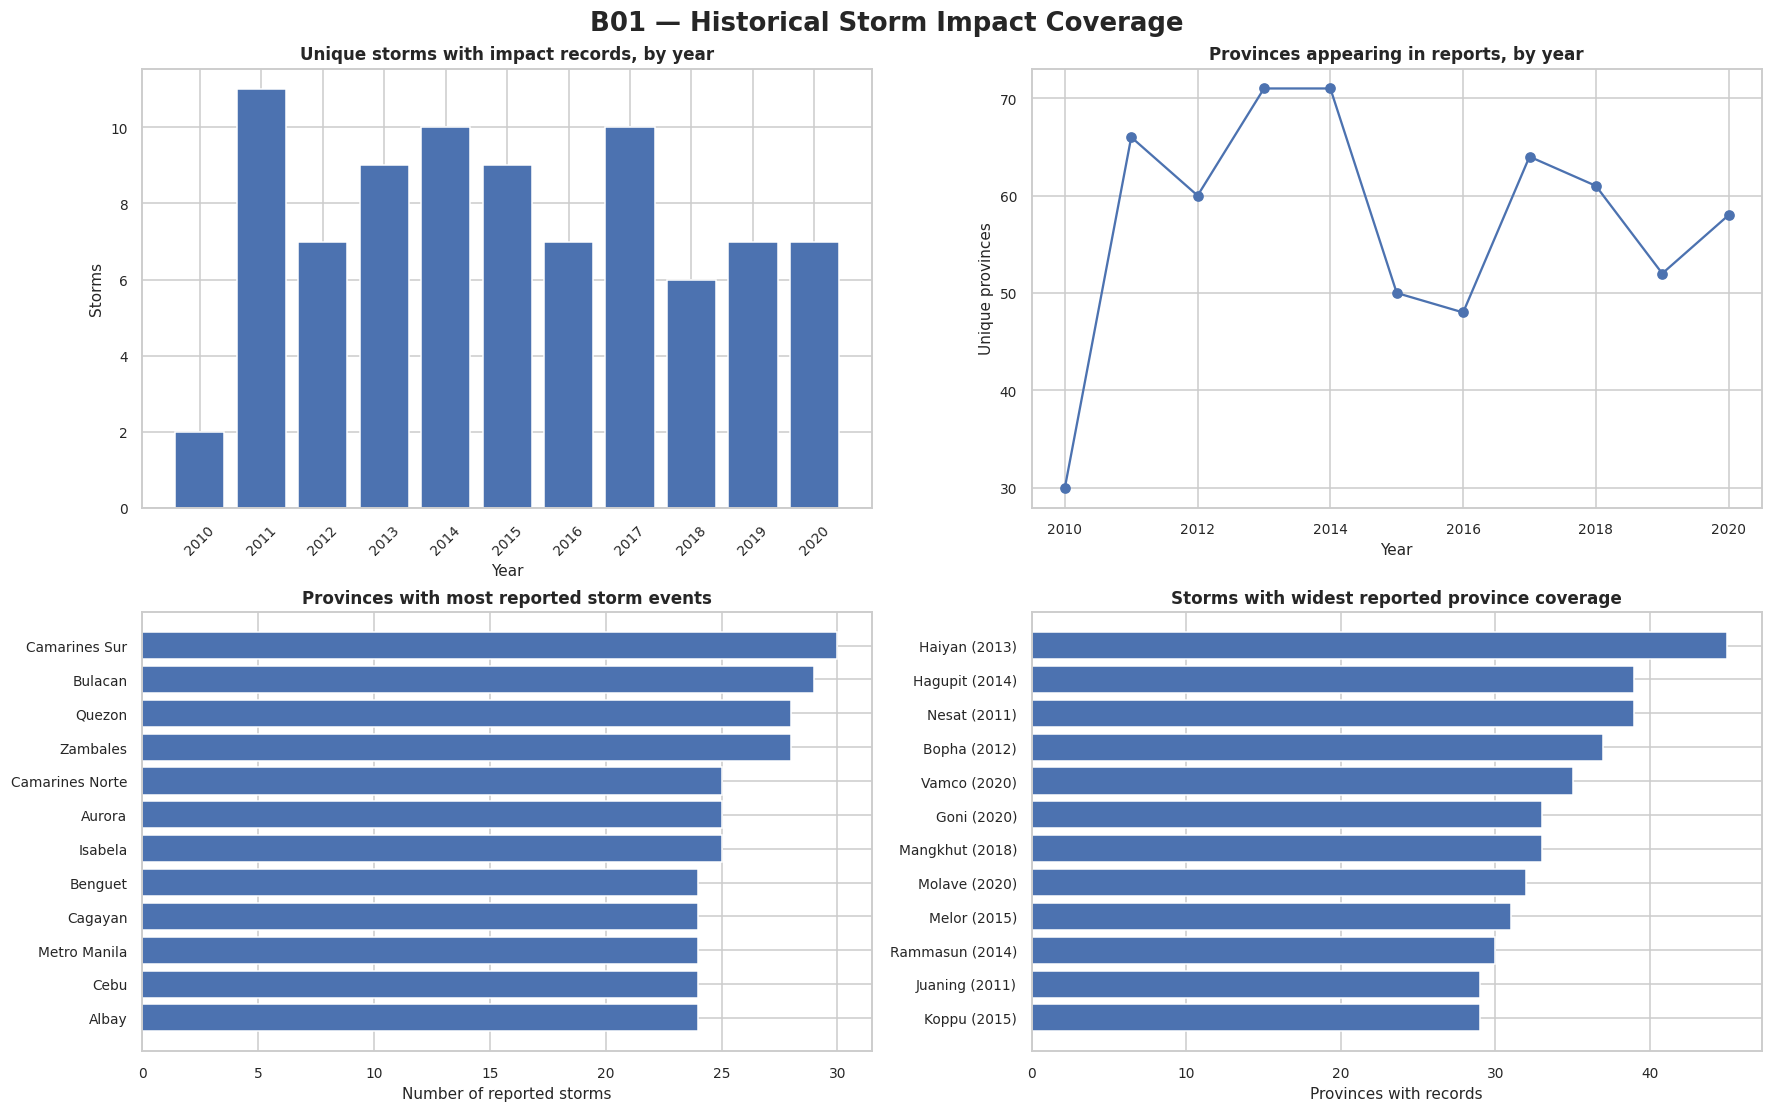

In [96]:
def b01_year_storms(ax):
    if annual.empty:return no_data(ax,'Historical impact storms by year')
    ax.bar(annual['year'].astype(int).astype(str),annual['unique_storms'])
    ax.set(title='Unique storms with impact records, by year',ylabel='Storms',xlabel='Year')
    ax.tick_params(axis='x',rotation=45)

def b01_year_provinces(ax):
    if coverage_by_year.empty:return no_data(ax,'Provincial impact coverage by year')
    ax.plot(coverage_by_year['year'],coverage_by_year['provinces_covered'],marker='o')
    ax.set(title='Provinces appearing in reports, by year',ylabel='Unique provinces',xlabel='Year')

def b01_provinces(ax):
    x=df.dropna(subset=['province','storm']).groupby('province')['event_label'].nunique()
    horiz_bars(ax,x,'Provinces with most reported storm events','Number of reported storms')

def b01_storms(ax):
    x=df.dropna(subset=['province','storm']).groupby('event_label')['province'].nunique()
    horiz_bars(ax,x,'Storms with widest reported province coverage','Provinces with records')

plot_grid('B01 — Historical Storm Impact Coverage',[
    b01_year_storms,b01_year_provinces,b01_provinces,b01_storms
])

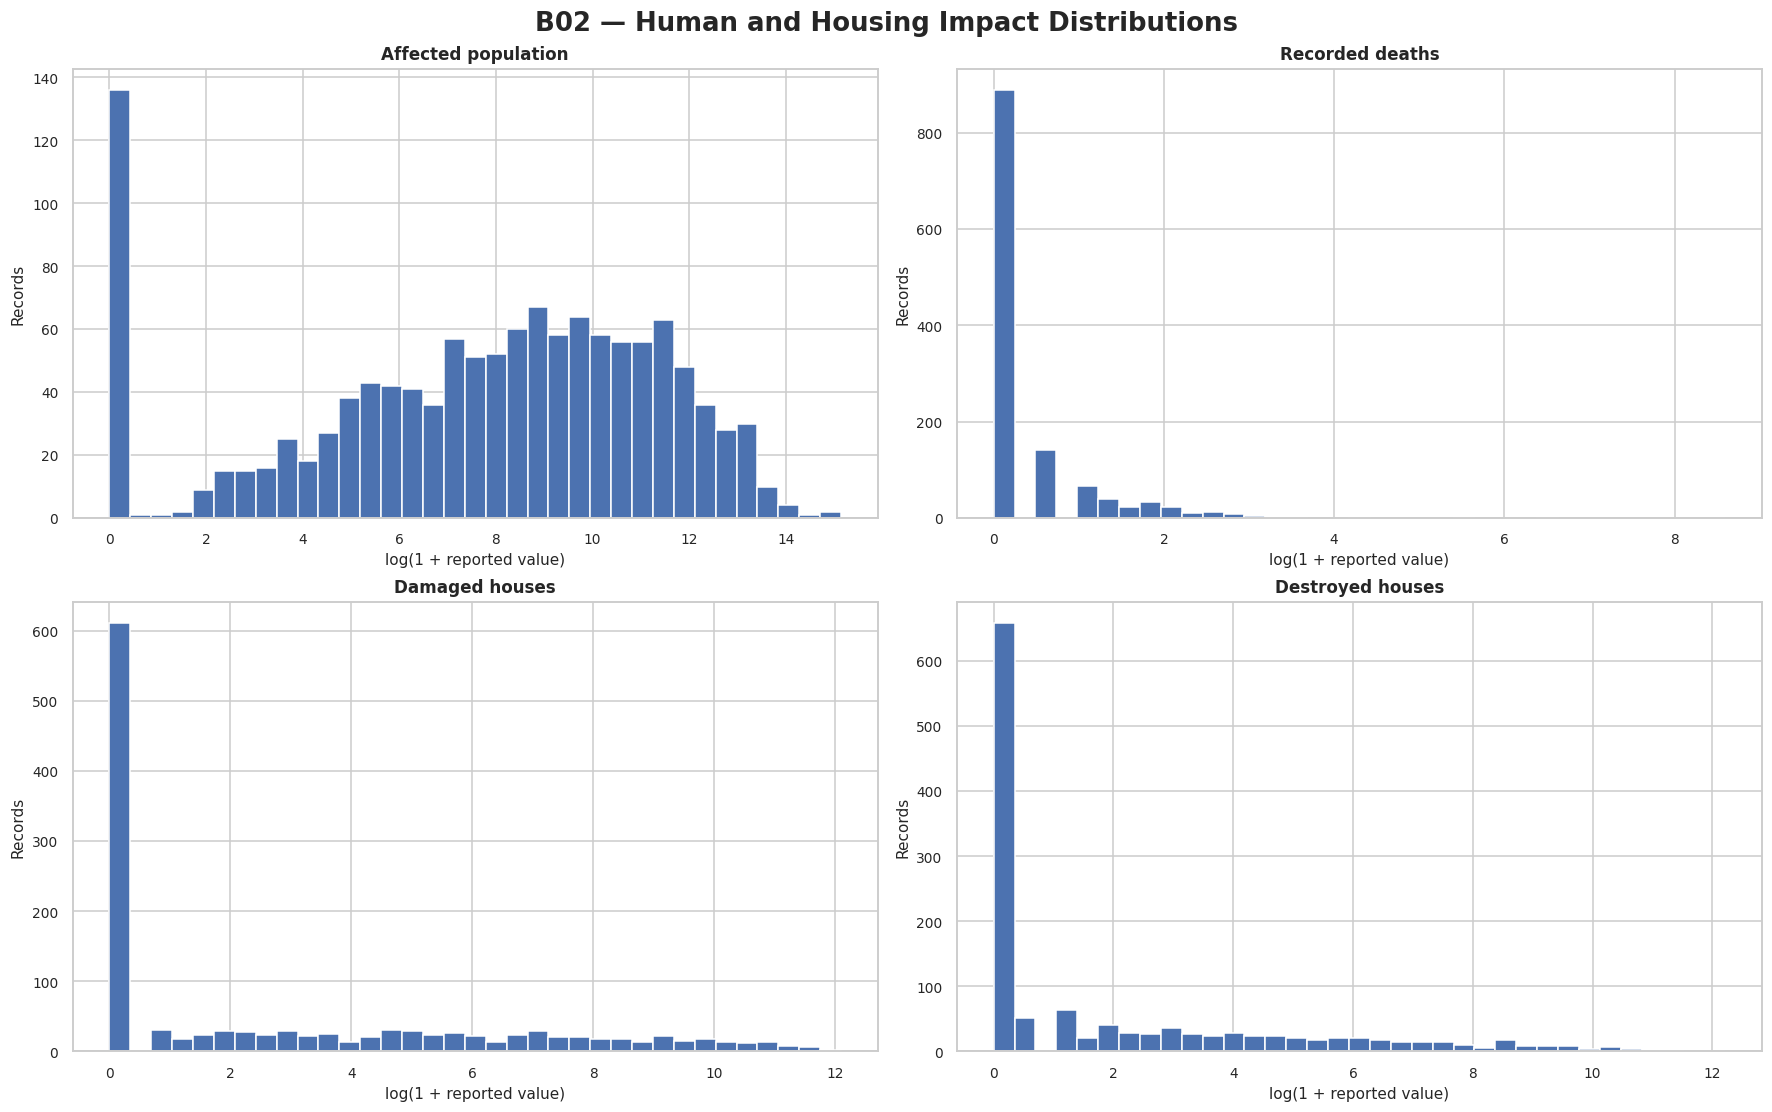

In [97]:
plot_grid('B02 — Human and Housing Impact Distributions',[
    lambda ax:dist_plot(ax,'affected','Affected population'),
    lambda ax:dist_plot(ax,'deaths','Recorded deaths'),
    lambda ax:dist_plot(ax,'houses_damaged','Damaged houses'),
    lambda ax:dist_plot(ax,'houses_destroyed','Destroyed houses')
])

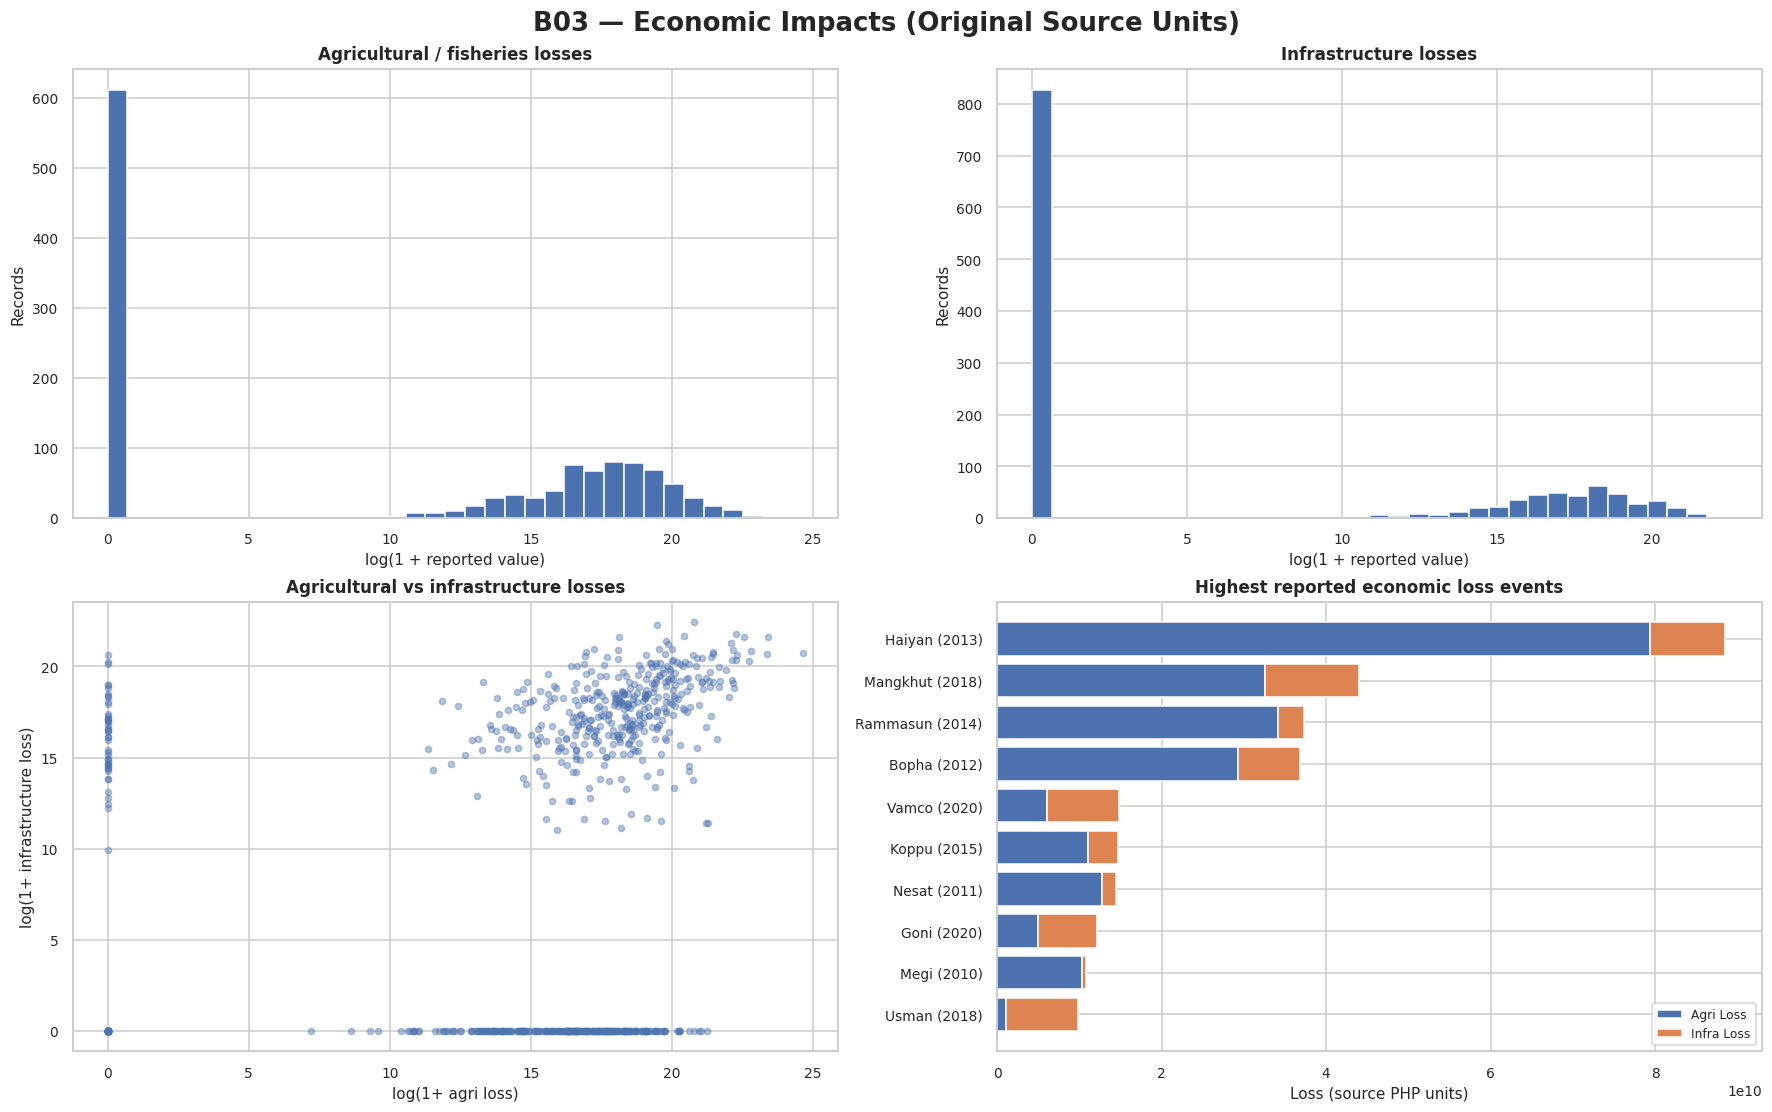

In [98]:
def b03_loss(ax, field, name):
    dist_plot(ax,field,name)

def b03_economic_scatter(ax):
    if not mapping['agri_loss'] or not mapping['infra_loss']:
        return no_data(ax,'Agriculture vs infrastructure losses')
    sub=df[['agri_loss','infra_loss']].dropna()
    sub=sub[(sub.agri_loss>=0)&(sub.infra_loss>=0)]
    if sub.empty:return no_data(ax,'Agriculture vs infrastructure losses')
    ax.scatter(np.log1p(sub.agri_loss),np.log1p(sub.infra_loss),s=16,alpha=.4)
    ax.set(title='Agricultural vs infrastructure losses',xlabel='log(1+ agri loss)',ylabel='log(1+ infrastructure loss)')

def b03_losses_by_storm(ax):
    fields=[f for f in ['agri_loss','infra_loss'] if mapping[f] is not None]
    if not fields or not mapping['storm']:
        return no_data(ax,'Largest reported economic losses')
    totals=df.groupby('event_label')[fields].sum(min_count=1).fillna(0).clip(lower=0)
    totals['sum']=totals.sum(axis=1)
    top=totals.nlargest(10,'sum').sort_values('sum')
    y=np.arange(len(top)); left=np.zeros(len(top))
    for field in fields:
        ax.barh(y,top[field].values,left=left,label=field.replace('_',' ').title())
        left += top[field].values
    ax.set_yticks(y,top.index.astype(str));ax.set(title='Highest reported economic loss events',xlabel='Loss (source PHP units)')
    ax.legend(fontsize=8)

plot_grid('B03 — Economic Impacts (Original Source Units)',[
    lambda ax:b03_loss(ax,'agri_loss','Agricultural / fisheries losses'),
    lambda ax:b03_loss(ax,'infra_loss','Infrastructure losses'),
    b03_economic_scatter,b03_losses_by_storm
])

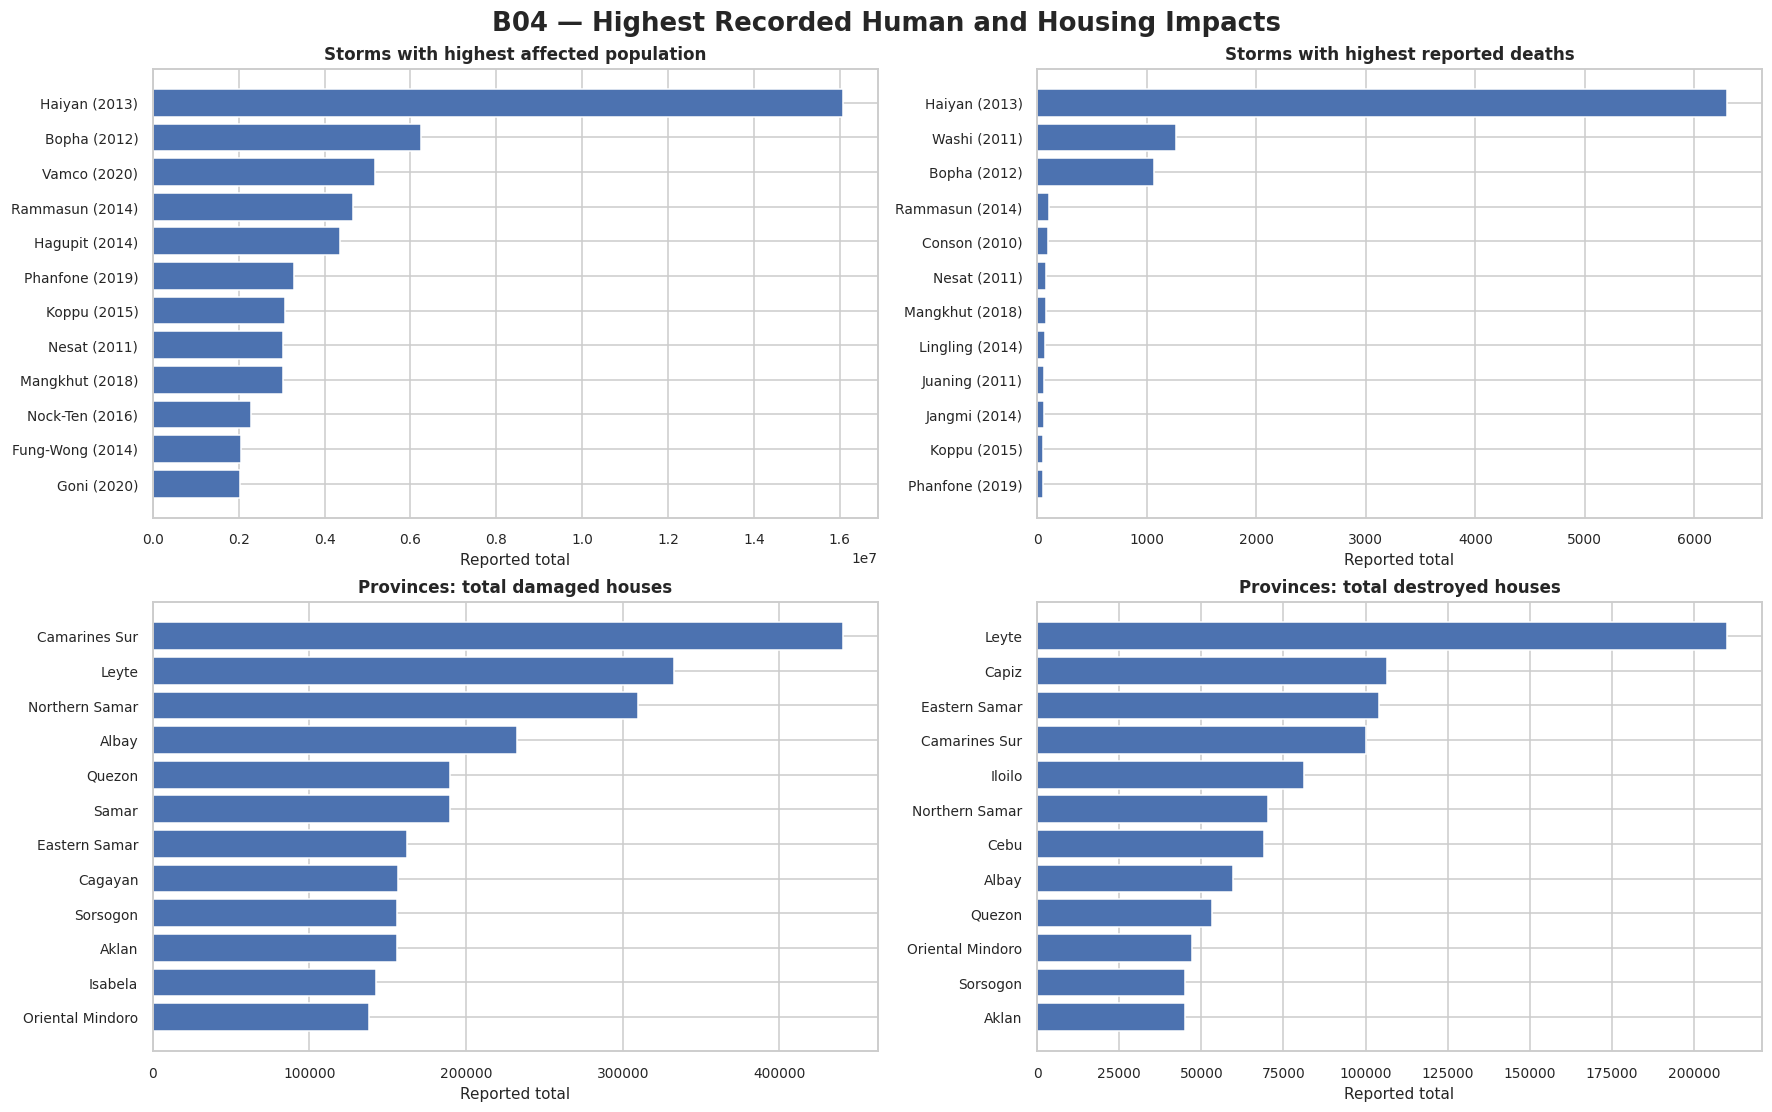

In [99]:
def b04_top_storms(ax,f,title):
    if mapping[f] is None or mapping['storm'] is None:return no_data(ax,title)
    vals=df.groupby('event_label')[f].sum(min_count=1)
    horiz_bars(ax,vals,title,'Reported total')

def b04_top_province(ax,f,title):
    if mapping[f] is None or mapping['province'] is None:return no_data(ax,title)
    vals=df.groupby('province')[f].sum(min_count=1)
    horiz_bars(ax,vals,title,'Reported total')

plot_grid('B04 — Highest Recorded Human and Housing Impacts',[
 lambda ax:b04_top_storms(ax,'affected','Storms with highest affected population'),
 lambda ax:b04_top_storms(ax,'deaths','Storms with highest reported deaths'),
 lambda ax:b04_top_province(ax,'houses_damaged','Provinces: total damaged houses'),
 lambda ax:b04_top_province(ax,'houses_destroyed','Provinces: total destroyed houses')
])

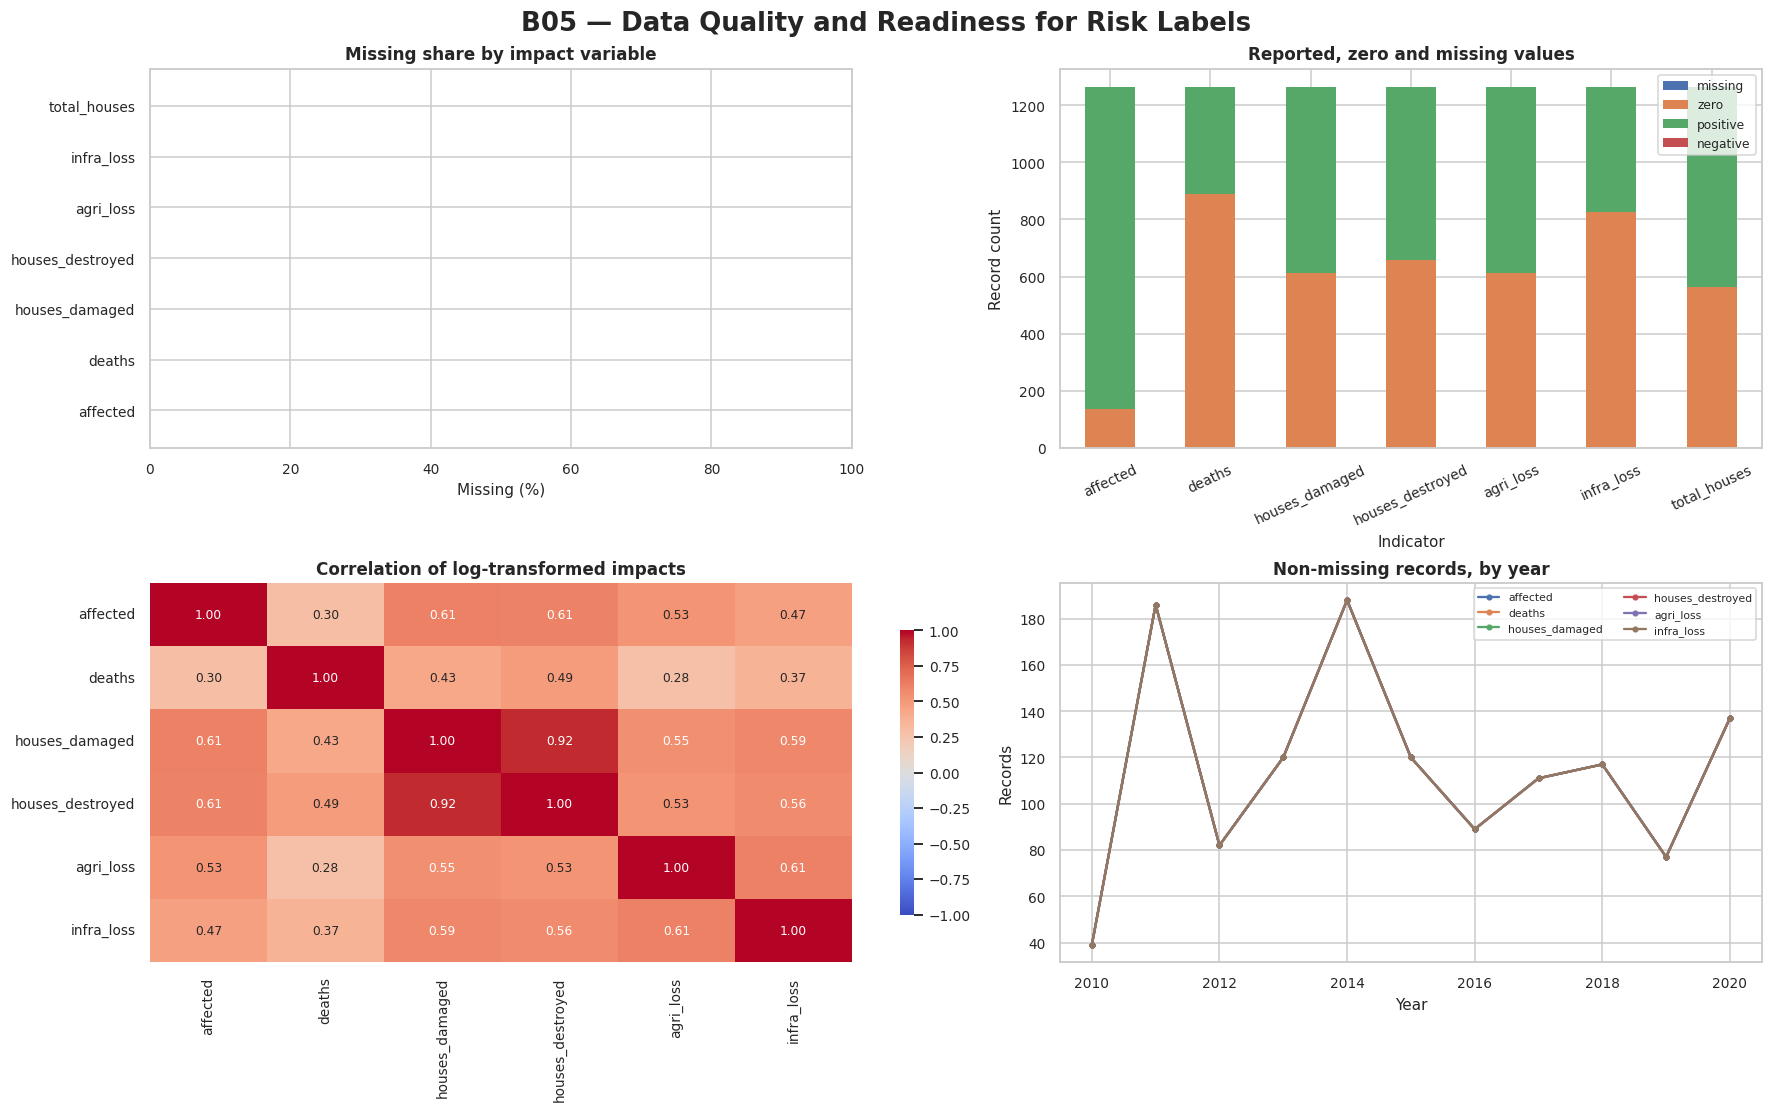

In [100]:
def b05_missing(ax):
    if quality.empty:return no_data(ax,'Missingness')
    ax.barh(quality['indicator'],quality['missing_%'])
    ax.set(title='Missing share by impact variable',xlabel='Missing (%)',xlim=(0,100))

def b05_status(ax):
    if status.empty:return no_data(ax,'Values by status')
    vals=status.set_index('indicator')[['missing','zero','positive','negative']]
    vals.plot(kind='bar',stacked=True,ax=ax,edgecolor='none')
    ax.set(title='Reported, zero and missing values',ylabel='Record count',xlabel='Indicator')
    ax.tick_params(axis='x',rotation=25);ax.legend(fontsize=8)

def b05_corr(ax):
    present=[f for f in MEASURES if mapping[f] is not None]
    if len(present)<2:return no_data(ax,'Cross-indicator correlations','Need at least 2 mapped impact indicators')
    numeric=df[present].where(df[present]>=0)
    if numeric.dropna(how='all').empty:return no_data(ax,'Cross-indicator correlations')
    c=np.log1p(numeric).corr(min_periods=3)
    if c.isna().all().all():return no_data(ax,'Cross-indicator correlations')
    sns.heatmap(c,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1,ax=ax,
                cbar_kws={'shrink':.75},annot_kws={'size':8})
    ax.set_title('Correlation of log-transformed impacts')

def b05_coverage(ax):
    present=[f for f in MEASURES if mapping[f] is not None]
    if not present or df['year'].isna().all():return no_data(ax,'Indicator coverage by year')
    cov=df.groupby('year')[present].count()
    if cov.empty:return no_data(ax,'Indicator coverage by year')
    for f in present:ax.plot(cov.index,cov[f],label=f,marker='.',linewidth=1.5)
    ax.set(title='Non-missing records, by year',xlabel='Year',ylabel='Records')
    ax.legend(fontsize=7,ncol=2)

plot_grid('B05 — Data Quality and Readiness for Risk Labels',[
 b05_missing,b05_status,b05_corr,b05_coverage
])

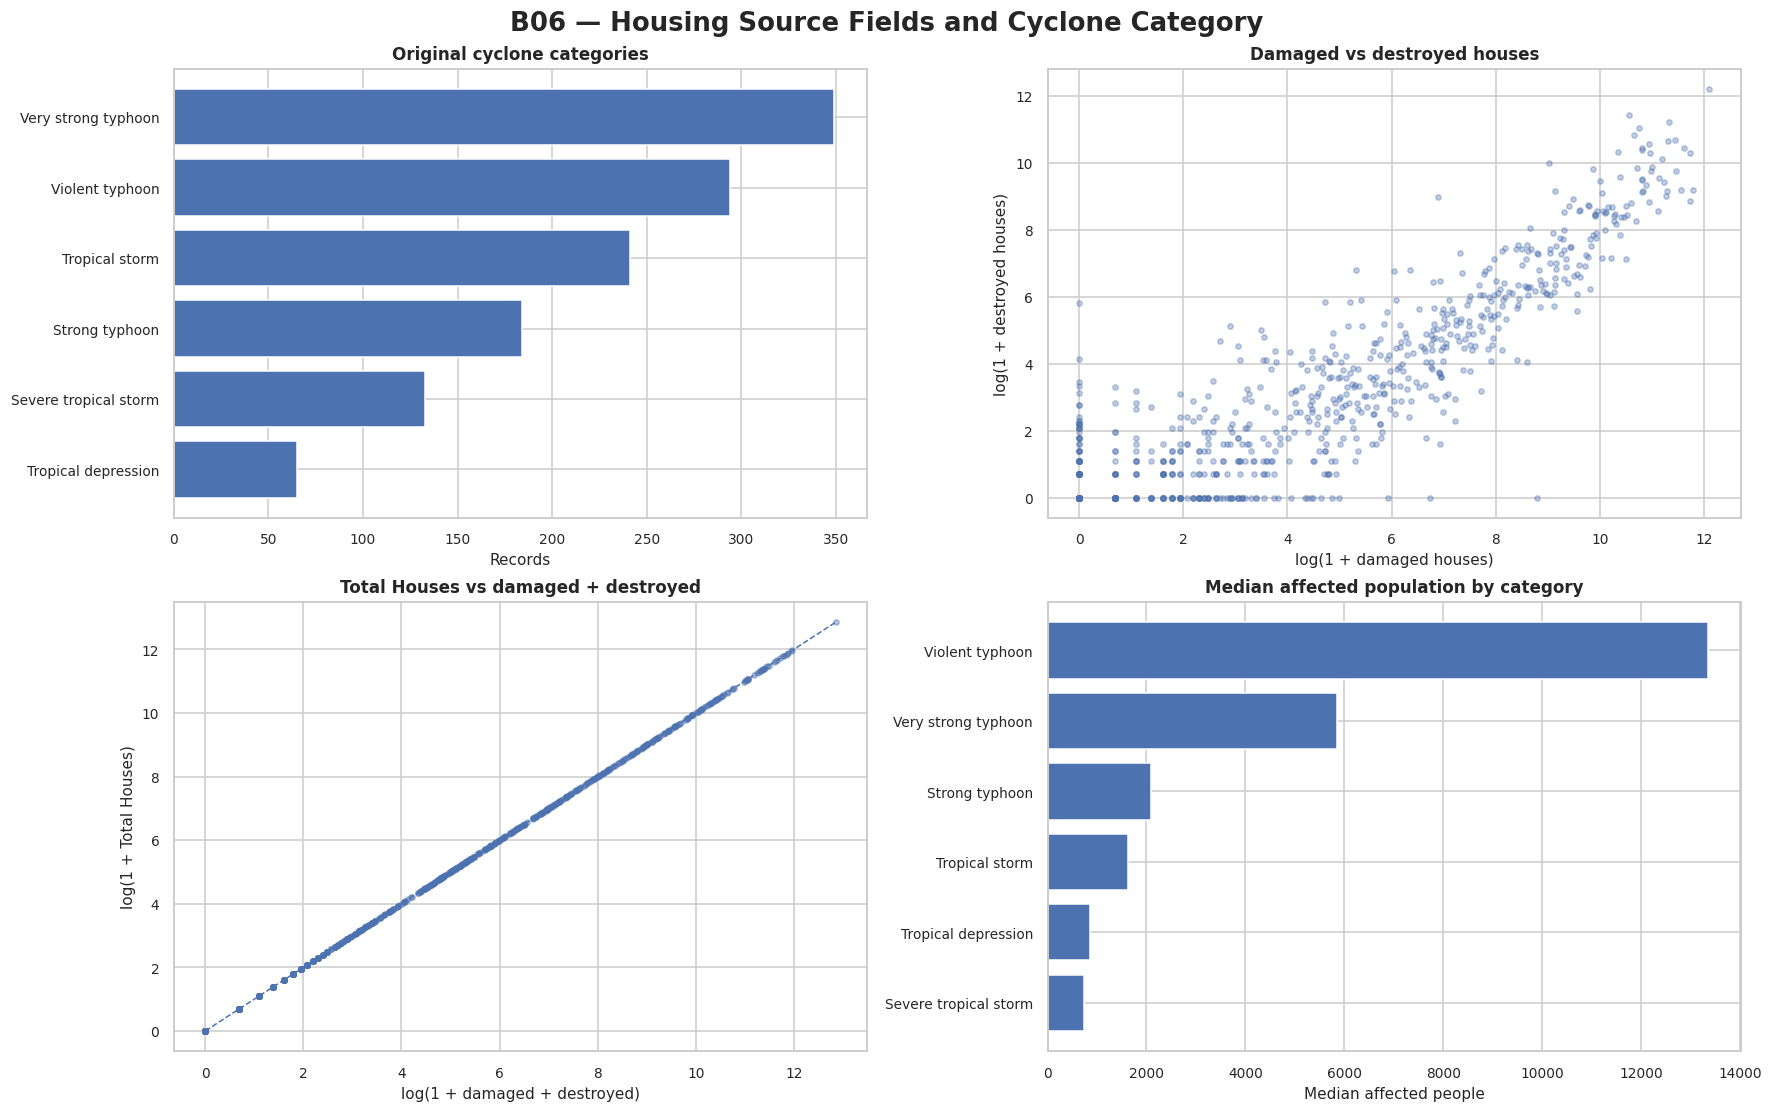

In [101]:
def b06_categories(ax):
    counts = df['category'].dropna().value_counts().head(12)
    horiz_bars(ax, counts, 'Original cyclone categories', 'Records', n=12)

def b06_housing_scatter(ax):
    x = df[['houses_damaged', 'houses_destroyed']].dropna()
    x = x[(x['houses_damaged'] >= 0) & (x['houses_destroyed'] >= 0)]
    if x.empty: return no_data(ax, 'Damaged vs destroyed houses')
    ax.scatter(np.log1p(x['houses_damaged']), np.log1p(x['houses_destroyed']), alpha=.35, s=12)
    ax.set(title='Damaged vs destroyed houses', xlabel='log(1 + damaged houses)',
           ylabel='log(1 + destroyed houses)')

def b06_housing_total(ax):
    if housing.empty: return no_data(ax, 'Total Houses vs sum of damage types')
    x = housing[(housing['total_houses'] >= 0) & (housing['damaged_plus_destroyed'] >= 0)]
    if x.empty: return no_data(ax, 'Total Houses vs sum of damage types')
    xx = np.log1p(x['damaged_plus_destroyed']); yy = np.log1p(x['total_houses'])
    ax.scatter(xx, yy, s=12, alpha=.4)
    if len(x):
        mx = max(xx.max(), yy.max()); ax.plot([0, mx], [0, mx], linestyle='--', linewidth=1)
    ax.set(title='Total Houses vs damaged + destroyed',
           xlabel='log(1 + damaged + destroyed)', ylabel='log(1 + Total Houses)')

def b06_category_impact(ax):
    sub = df[['category', 'affected']].dropna()
    sub = sub[sub['affected'] >= 0]
    if sub.empty: return no_data(ax, 'Affected population by category')
    popular = sub['category'].value_counts().head(8).index
    meds = sub[sub['category'].isin(popular)].groupby('category')['affected'].median()
    horiz_bars(ax, meds, 'Median affected population by category',
               'Median affected people', n=8)

plot_grid('B06 — Housing Source Fields and Cyclone Category',[
    b06_categories, b06_housing_scatter,
    b06_housing_total, b06_category_impact
])
